# Nigeria House Price Prediction
## Exploration, data cleaning, modelling and deployment in one notebook

| | |
|---|---|
| **Problem** | Estimate the asking price of a residential property in Nigeria from its characteristics. |
| **Problem type** | Supervised machine learning, regression (continuous target: price in Naira). |
| **Planned solution** | Train and compare regression models, then serve the selected model in a Streamlit app. |
| **Inputs available** | State, town, property type, bedrooms, bathrooms, toilets, parking spaces. *The dataset contains no property size.* |
| **Output** | Estimated asking price in Nigerian Naira (₦). |
| **Dataset source** | https://drive.google.com/file/d/1kHXOsC55G8Jmz2v8eWgpKFO2suQQwyE7/view |
| **Live app:** | https://nigeria-house-price-predictor-t.streamlit.app/ |

### Technical objectives
1. Understand and explore the housing dataset.
2. Assess data quality and prepare the data for modelling.
3. Identify relevant features and their relationships with price.
4. Develop and experiment with suitable regression algorithms.
5. Evaluate models with appropriate regression metrics.
6. Compare candidate models and select one based on evidence.
7. Integrate the selected model into a Streamlit application.
8. Test, document and prepare the complete solution for submission.

### Quality expectations
**Functional** (model and app work), **Reproducible** (another person can rerun the workflow), **Properly evaluated** (appropriate metrics), **Transparent** (assumptions, limitations and error sources documented), **Evidence-based** (choices backed by the data).

---
### How this notebook is organised
| Part | Tasks | What happens |
|---|---|---|
| **1. Data exploration** | 1 to 13 | Understand the raw data. Nothing is modified. |
| **2. Data cleaning** | 14 to 20 | Correct state labels, remove exact duplicates, split, remove implausible prices, summarise what was removed, package the steps as reusable code. |
| **3. Feature preparation** | 21 to 22 | Build the model inputs and estimate the accuracy ceiling. |
| **4. Model development** | 23 to 24 | Baselines and candidate models compared with 5-fold cross-validation; tuning and selection. |
| **5. Model evaluation** | 25 to 27 | One evaluation on a random hold-out set, error by region, feature importance. |
| **6. Deployment** | 28 to 29 | Model, supporting files, Streamlit app, consistency checks. |
| **7. Conclusion** | 30 | Results, interpretation, assumptions and limitations. |

Every task follows **Purpose, Method, Finding, Decision**. Numbers quoted in Findings are computed by the code, not typed by hand. Run the notebook top to bottom (Restart & Run All): it needs only `nigeria_houses_data.csv` next to it and creates every other file (cleaned data, Python modules, saved model, Streamlit app, tests, requirements). `df_raw` is the untouched original and is never modified.

## Setup

In [1]:
from pathlib import Path
import inspect
import pprint
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")
import warnings
# seaborn passes a keyword that newer Matplotlib versions deprecate; harmless, hidden to keep outputs readable
warnings.filterwarnings("ignore", message=".*vert.*deprecated.*")
RANDOM_STATE = 42

NUM_COLS = ["bedrooms", "bathrooms", "toilets", "parking_space"]
CAT_COLS = ["title", "town", "state"]
KEY_COLS = NUM_COLS + CAT_COLS + ["price"]   # the columns that define "the same listing"


def naira(x, decimals=1):
    """Format a Naira amount compactly, e.g. 85_000_000 -> ₦85.0M."""
    if pd.isna(x):
        return "-"
    x = float(x)
    for limit, suffix in [(1e12, "T"), (1e9, "B"), (1e6, "M"), (1e3, "K")]:
        if abs(x) >= limit:
            return f"₦{x / limit:,.{decimals}f}{suffix}"
    return f"₦{x:,.0f}"


def show(frame, money=(), pct=(), max_rows=25, index=True, decimals=3):
    """Display a table with Naira / percent formatting applied only to the named columns."""
    out = frame.head(max_rows).copy()
    for c in money:
        out[c] = out[c].map(naira)
    for c in pct:
        out[c] = out[c].map(lambda v: f"{v:.1f}%")
    if not (money or pct):
        out = out.round(decimals)
    display(out if index else out.reset_index(drop=True))
    if len(frame) > max_rows:
        print(f"... showing {max_rows} of {len(frame):,} rows")


def md(text):
    display(Markdown(text))


def describe_numeric(frame, cols, money_cols=("price",)):
    d = frame[list(cols)].describe().T
    out = d.astype(object)
    out["count"] = d["count"].astype(int)
    for c in money_cols:
        if c in out.index:
            for stat in ["mean", "std", "min", "25%", "50%", "75%", "max"]:
                out.loc[c, stat] = naira(d.loc[c, stat])
    return out


def naira_axis(ax, axis="x"):
    fmt = plt.FuncFormatter(lambda v, _: naira(v, 0))
    (ax.xaxis if axis == "x" else ax.yaxis).set_major_formatter(fmt)

In [2]:
# To be completed by the author: where the data came from and under which terms it may be used.
DATASET_SOURCE = "[Add the dataset source link here]"
DATASET_LICENCE = "[Add the licence or terms of use here]"

# Part 1: Data exploration (raw data, read-only)

## Task 1: Load the dataset
**Purpose.** Load the data once, from one explicit path.
**Method.** `pd.read_csv` on a single path, plus a check that the expected columns exist. Place `nigeria_houses_data.csv` next to this notebook (in Colab, upload it to the session files).

In [3]:
DATA_PATH = Path("nigeria_houses_data.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. Place nigeria_houses_data.csv next to this notebook."
    )

df_raw = pd.read_csv(DATA_PATH)   # read-only original: never modified below

expected = set(KEY_COLS)
assert expected <= set(df_raw.columns), f"Missing columns: {expected - set(df_raw.columns)}"
print(f"Loaded {DATA_PATH}: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")

Loaded nigeria_houses_data.csv: 24,326 rows x 8 columns


## Task 2: Inspect structure and summary statistics
**Purpose.** Understand what a row and a column represent and spot obvious problems.
**Method.** First and last rows, data types, numeric and categorical summaries.

In [4]:
md("**First 5 rows**")
show(df_raw.head(), money=["price"], max_rows=5)
md("**Last 5 rows**")
show(df_raw.tail(), money=["price"], max_rows=5)
md("**Data types**")
display(df_raw.dtypes.astype(str).to_frame("dtype"))
md("**Numeric summary**")
display(describe_numeric(df_raw, NUM_COLS + ["price"]))
md("**Categorical summary**")
display(df_raw[CAT_COLS].describe().T)

n_rows = len(df_raw)
md(f"""**Finding.** {n_rows:,} listings, {df_raw.shape[1]} columns: four property counts, three categorical columns and the target `price`. There is no size, age, condition, date or listing identifier.

**Decision.** Treat each row as one listing. Record the missing predictors (especially size) as a limitation of the final model.""")

**First 5 rows**

,bedrooms,bathrooms,toilets,parking_space,title,town,state,price
0,6.0,5.0,5.0,4.0,Detached Duplex,Mabushi,Abuja,₦450.0M
1,4.0,5.0,5.0,4.0,Terraced Duplexes,Katampe,Abuja,₦800.0M
2,4.0,5.0,5.0,4.0,Detached Duplex,Lekki,Lagos,₦120.0M
3,4.0,4.0,5.0,6.0,Detached Duplex,Ajah,Lagos,₦40.0M
4,4.0,4.0,5.0,2.0,Semi Detached Duplex,Lekki,Lagos,₦75.0M


**Last 5 rows**

,bedrooms,bathrooms,toilets,parking_space,title,town,state,price
24321,2.0,2.0,2.0,4.0,Block of Flats,Kabusa,Abuja,₦15.0M
24322,4.0,5.0,5.0,4.0,Block of Flats,Ado-Odo/Ota,Ogun,₦25.0M
24323,4.0,5.0,5.0,4.0,Detached Duplex,Lekki,Lagos,₦68.0M
24324,3.0,4.0,4.0,3.0,Block of Flats,Victoria Island (VI),Lagos,₦78.0M
24325,4.0,5.0,5.0,4.0,Detached Duplex,Lekki,Lagos,₦65.0M


**Data types**

,dtype
bedrooms,float64
bathrooms,float64
toilets,float64
parking_space,float64
title,str
town,str
state,str
price,float64


**Numeric summary**

,count,mean,std,min,25%,50%,75%,max
bedrooms,24326,4.338814,1.138497,1.0,4.0,4.0,5.0,9.0
bathrooms,24326,4.600798,1.163161,1.0,4.0,5.0,5.0,9.0
toilets,24326,5.176355,1.226253,1.0,5.0,5.0,6.0,9.0
parking_space,24326,4.041725,1.399936,1.0,4.0,4.0,4.0,9.0
price,24326,₦301.4M,₦12.2B,₦90.0K,₦52.0M,₦85.0M,₦160.0M,₦1.8T


**Categorical summary**

,count,unique,top,freq
title,24326,7,Detached Duplex,13992
town,24326,189,Lekki,10895
state,24326,25,Lagos,18445


**Finding.** 24,326 listings, 8 columns: four property counts, three categorical columns and the target `price`. There is no size, age, condition, date or listing identifier.

**Decision.** Treat each row as one listing. Record the missing predictors (especially size) as a limitation of the final model.

## Task 3: Assess data quality
**Purpose.** Check for missing values and exact duplicates.
**Method.** Count missing cells, exact duplicate rows and unique values per column.

In [5]:
missing = pd.DataFrame({"missing": df_raw.isna().sum(), "missing_%": (df_raw.isna().mean() * 100).round(2)})
display(missing)
display(df_raw.nunique().to_frame("unique_values"))

n_missing = int(df_raw.isna().sum().sum())
n_dup = int(df_raw.duplicated().sum())
md(f"""**Finding.** {n_missing} missing cells. {n_dup:,} rows ({n_dup / len(df_raw):.1%}) are exact copies of an earlier row.

**Decision.** No imputation is needed. The duplicates are investigated in Task 4 and handled in Task 16.""")

,missing,missing_%
bedrooms,0,0.0
bathrooms,0,0.0
toilets,0,0.0
parking_space,0,0.0
title,0,0.0
town,0,0.0
state,0,0.0
price,0,0.0


,unique_values
bedrooms,9
bathrooms,9
toilets,9
parking_space,9
title,7
town,189
state,25
price,539


**Finding.** 0 missing cells. 10,438 rows (42.9%) are exact copies of an earlier row.

**Decision.** No imputation is needed. The duplicates are investigated in Task 4 and handled in Task 16.

## Task 4: Investigate duplicate records
**Purpose.** Understand how large and how concentrated the duplication is before deciding what to do.
**Method.** Count duplicate occurrences, list the most repeated rows, and compare where duplicates sit against where all rows sit.

In [6]:
in_group = df_raw.duplicated(keep=False)
dup_occ = df_raw[df_raw.duplicated(keep="first")]
summary = pd.Series({
    "Rows in file": len(df_raw),
    "Duplicate occurrences (beyond the first)": len(dup_occ),
    "Rows belonging to a duplicated group": int(in_group.sum()),
    "Distinct repeated row patterns": len(df_raw[in_group].drop_duplicates()),
    "Rows left after exact de-duplication": len(df_raw) - len(dup_occ),
}, name="count")
display(summary.map("{:,}".format).to_frame())

md("**10 most repeated listings**")
top_rep = (df_raw.groupby(list(df_raw.columns), as_index=False).size()
           .rename(columns={"size": "frequency"}).sort_values("frequency", ascending=False))
show(top_rep, money=["price"], max_rows=10, index=False)


def share_table(col, n=5):
    d = dup_occ[col].value_counts(normalize=True).mul(100)
    a = df_raw[col].value_counts(normalize=True).mul(100)
    t = pd.DataFrame({"share_of_duplicates_%": d, "share_of_all_rows_%": a})
    return t.sort_values("share_of_duplicates_%", ascending=False).head(n).round(1)


for col in ["state", "town", "title"]:
    md(f"**Where duplicates sit: {col}**")
    display(share_table(col))

top_state = dup_occ["state"].value_counts(normalize=True)
top_town = dup_occ["town"].value_counts(normalize=True)
all_share = (df_raw["state"] == top_state.index[0]).mean()
md(f"""**Finding.** {len(dup_occ):,} rows ({len(dup_occ) / len(df_raw):.1%}) repeat an earlier row exactly. {top_state.index[0]} accounts for {top_state.iloc[0]:.1%} of the duplicates against {all_share:.1%} of all rows, mainly in {top_town.index[0]}. The cause cannot be established from the data: with no listing ID, size or date, a scraping repeat cannot be told apart from several genuinely identical units.

**Decision.** De-duplicate (Task 16), but only after the labels are fixed, and document it as an assumption.""")

... showing 10 of 13,888 rows


,count
Rows in file,"24,326"
Duplicate occurrences (beyond the first),"10,438"
Rows belonging to a duplicated group,"12,719"
Distinct repeated row patterns,"2,281"
Rows left after exact de-duplication,"13,888"


**10 most repeated listings**

,bedrooms,bathrooms,toilets,parking_space,title,town,state,price,frequency
0,5.0,5.0,6.0,4.0,Detached Duplex,Lekki,Lagos,₦120.0M,178
1,5.0,5.0,6.0,4.0,Detached Duplex,Lekki,Lagos,₦130.0M,144
2,5.0,5.0,6.0,4.0,Detached Duplex,Lekki,Lagos,₦140.0M,88
3,5.0,5.0,6.0,4.0,Detached Duplex,Lekki,Lagos,₦90.0M,82
4,5.0,5.0,6.0,4.0,Detached Duplex,Lekki,Lagos,₦125.0M,80
5,4.0,4.0,5.0,4.0,Detached Duplex,Ikoyi,Lagos,₦280.0M,79
6,5.0,5.0,6.0,4.0,Detached Duplex,Lekki,Lagos,₦95.0M,79
7,5.0,5.0,6.0,4.0,Detached Duplex,Lekki,Lagos,₦150.0M,79
8,4.0,5.0,5.0,4.0,Detached Duplex,Ajah,Lagos,₦65.0M,77
9,5.0,5.0,6.0,4.0,Detached Duplex,Lekki,Lagos,₦155.0M,75


**Where duplicates sit: state**

,share_of_duplicates_%,share_of_all_rows_%
state,,
Lagos,94.6,75.8
Abuja,3.9,14.5
Ogun,0.6,2.6
Oyo,0.4,2.0
Rivers,0.2,1.8


**Where duplicates sit: town**

,share_of_duplicates_%,share_of_all_rows_%
town,,
Lekki,71.4,44.8
Ajah,9.1,8.9
Ikoyi,6.5,6.4
Victoria Island (VI),1.6,2.0
Ikeja,1.6,2.8


**Where duplicates sit: title**

,share_of_duplicates_%,share_of_all_rows_%
title,,
Detached Duplex,72.3,57.5
Terraced Duplexes,12.0,13.3
Semi Detached Duplex,11.4,10.7
Detached Bungalow,2.2,8.7
Block of Flats,1.8,7.2


**Finding.** 10,438 rows (42.9%) repeat an earlier row exactly. Lagos accounts for 94.6% of the duplicates against 75.8% of all rows, mainly in Lekki. The cause cannot be established from the data: with no listing ID, size or date, a scraping repeat cannot be told apart from several genuinely identical units.

**Decision.** De-duplicate (Task 16), but only after the labels are fixed, and document it as an assumption.

## Task 5: Investigate the price distribution
**Purpose.** Understand the target variable: scale, skew and extreme values.
**Method.** Percentiles, threshold counts, the extreme records, the most common values, and a histogram on a log scale.

**Percentiles**

,price
1.0%,₦7.2M
5.0%,₦16.0M
10.0%,₦27.0M
25.0%,₦52.0M
50.0%,₦85.0M
75.0%,₦160.0M
90.0%,₦350.0M
95.0%,₦600.0M
99.0%,₦1.4B
99.9%,₦4.0B


**Rows beyond price thresholds**

,rows,share_%
below ₦1M,14,0.06
below ₦10M,441,1.81
above ₦500M,1365,5.61
above ₦1B,574,2.36
above ₦10B,17,0.07


**10 lowest and 10 highest prices**

,bedrooms,bathrooms,toilets,parking_space,title,town,state,price
2693,2.0,3.0,3.0,4.0,Terraced Duplexes,Ibeju Lekki,Lagos,₦90.0K
20146,2.0,2.0,3.0,4.0,Detached Bungalow,Mowe Town,Ogun,₦100.0K
2385,5.0,7.0,7.0,4.0,Semi Detached Duplex,Maitama District,Abuja,₦110.0K
2810,7.0,5.0,5.0,4.0,Detached Duplex,Isheri North,Lagos,₦350.0K
17645,7.0,7.0,8.0,6.0,Detached Duplex,Isheri North,Lagos,₦350.0K
17940,7.0,5.0,5.0,4.0,Detached Duplex,Isheri North,Lagos,₦350.0K
7083,5.0,5.0,6.0,4.0,Detached Duplex,Lekki,Lagos,₦400.0K
2449,2.0,2.0,2.0,1.0,Detached Duplex,Asokoro District,Abuja,₦462.8K
4176,2.0,7.0,8.0,7.0,Detached Duplex,Jos South,Plateau,₦500.0K
14555,4.0,4.0,5.0,4.0,Semi Detached Duplex,Ikoyi,Lagos,₦660.0K


**Most common price values**

,price,rows
0,₦65.0M,963
1,₦120.0M,874
2,₦75.0M,872
3,₦70.0M,748
4,₦130.0M,694
5,₦80.0M,687
6,₦60.0M,671
7,₦150.0M,643
8,₦90.0M,636
9,₦55.0M,615


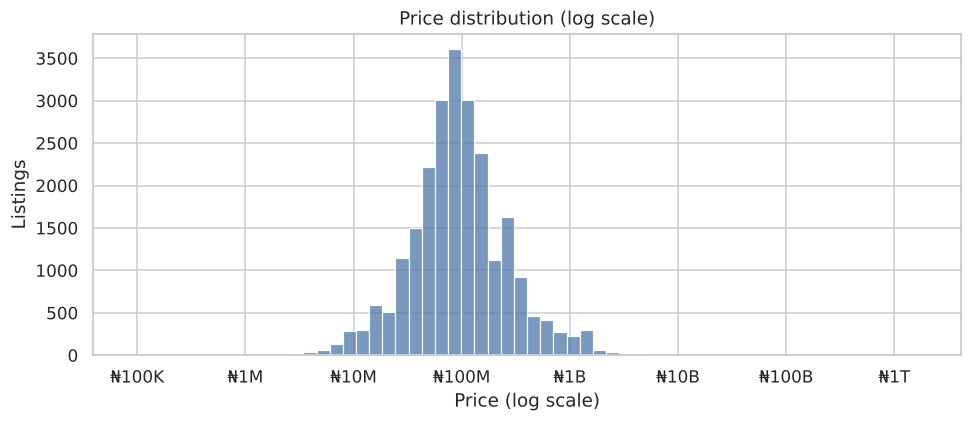

**Finding.** Median ₦85.0M against mean ₦301.4M (mean is 3.5x the median): the distribution is strongly right-skewed. Prices run from ₦90.0K to ₦1.8T. The classic IQR rule would call 2,558 rows (10.5%) outliers, too many to serve as a removal rule on a skewed target. 97% of prices are exact multiples of ₦1M, which suggests asking prices rather than recorded sale prices.

**Decision.** Model the log of price. Do not use a global cut-off to remove prices; implausible values are judged against comparable listings in Task 18.

In [7]:
price = df_raw["price"]
pcts = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
pt = price.quantile(pcts).to_frame("price")
pt.index = [f"{p:.1%}" for p in pcts]
md("**Percentiles**")
show(pt, money=["price"])

bands = {
    "below ₦1M": price < 1e6, "below ₦10M": price < 1e7,
    "above ₦500M": price > 5e8, "above ₦1B": price > 1e9, "above ₦10B": price > 1e10,
}
band_tbl = pd.DataFrame({"rows": {k: int(v.sum()) for k, v in bands.items()}})
band_tbl["share_%"] = (band_tbl["rows"] / len(price) * 100).round(2)
md("**Rows beyond price thresholds**")
display(band_tbl)

md("**10 lowest and 10 highest prices**")
show(pd.concat([df_raw.nsmallest(10, "price"), df_raw.nlargest(10, "price")]), money=["price"], max_rows=20)

md("**Most common price values**")
common = price.value_counts().head(10).rename_axis("price").reset_index(name="rows")
show(common, money=["price"], index=False)

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(np.log10(price), bins=60, ax=ax, color="#4C78A8")
ticks = [5, 6, 7, 8, 9, 10, 11, 12]
ax.set_xticks(ticks)
ax.set_xticklabels(["₦100K", "₦1M", "₦10M", "₦100M", "₦1B", "₦10B", "₦100B", "₦1T"])
ax.set_xlabel("Price (log scale)")
ax.set_ylabel("Listings")
ax.set_title("Price distribution (log scale)")
plt.tight_layout()
plt.show()

q1, q3 = price.quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
n_above = int((price > upper_fence).sum())
round_share = float((price % 1e6 == 0).mean())
md(f"""**Finding.** Median {naira(price.median())} against mean {naira(price.mean())} (mean is {price.mean() / price.median():.1f}x the median): the distribution is strongly right-skewed. Prices run from {naira(price.min())} to {naira(price.max())}. The classic IQR rule would call {n_above:,} rows ({n_above / len(price):.1%}) outliers, too many to serve as a removal rule on a skewed target. {round_share:.0%} of prices are exact multiples of ₦1M, which suggests asking prices rather than recorded sale prices.

**Decision.** Model the log of price. Do not use a global cut-off to remove prices; implausible values are judged against comparable listings in Task 18.""")

## Task 6: Investigate categorical features
**Purpose.** Check the cardinality, balance and formatting of `title`, `town` and `state`.
**Method.** Level counts, whitespace and case checks, and the top 10 levels of each column.

In [8]:
rows = []
for col in CAT_COLS:
    s = df_raw[col]
    rows.append({
        "column": col,
        "unique_levels": int(s.nunique()),
        "levels_with_<10_rows": int((s.value_counts() < 10).sum()),
        "whitespace_issues": int((s != s.str.strip()).sum()),
        "case_variants": int(s.nunique() - s.str.strip().str.lower().nunique()),
    })
display(pd.DataFrame(rows).set_index("column"))

for col in CAT_COLS:
    vc = df_raw[col].value_counts()
    t = pd.DataFrame({"rows": vc, "share_%": (vc / len(df_raw) * 100).round(2)}).head(10)
    md(f"**{col}: top 10 of {vc.size} levels**")
    display(t)

lag_abj = df_raw["state"].isin(["Lagos", "Abuja"]).mean()
top_title = df_raw["title"].value_counts(normalize=True)
top_town_share = df_raw["town"].value_counts(normalize=True)
ws_total = sum(r["whitespace_issues"] for r in rows)
case_total = sum(r["case_variants"] for r in rows)
md(f"""**Finding.** {ws_total} whitespace problems and {case_total} capitalisation variants across the three columns. Lagos and Abuja hold {lag_abj:.1%} of the rows, {top_title.index[0]} is {top_title.iloc[0]:.1%} of all listings and {top_town_share.index[0]} alone is {top_town_share.iloc[0]:.1%}. The dataset is geographically concentrated, and many towns have very few listings.

**Decision.** Predictions outside Lagos and Abuja will be less reliable; this goes in the limitations. Rare towns are handled at the modelling stage (grouping or target encoding).""")

,unique_levels,levels_with_<10_rows,whitespace_issues,case_variants
column,,,,
title,7,0,0,0
town,189,99,0,0
state,25,12,0,0


**title: top 10 of 7 levels**

,rows,share_%
title,,
Detached Duplex,13992,57.52
Terraced Duplexes,3237,13.31
Semi Detached Duplex,2615,10.75
Detached Bungalow,2108,8.67
Block of Flats,1745,7.17
Semi Detached Bungalow,452,1.86
Terraced Bungalow,177,0.73


**town: top 10 of 189 levels**

,rows,share_%
town,,
Lekki,10895,44.79
Ajah,2164,8.90
Ikoyi,1547,6.36
Ikeja,688,2.83
Ibeju Lekki,503,2.07
Victoria Island (VI),496,2.04
Port Harcourt,435,1.79
Ibadan,413,1.70
Gwarinpa,391,1.61


**state: top 10 of 25 levels**

,rows,share_%
state,,
Lagos,18445,75.82
Abuja,3524,14.49
Ogun,637,2.62
Oyo,477,1.96
Rivers,444,1.83
Imo,246,1.01
Anambara,145,0.60
Enugu,128,0.53
Edo,100,0.41


**Finding.** 0 whitespace problems and 0 capitalisation variants across the three columns. Lagos and Abuja hold 90.3% of the rows, Detached Duplex is 57.5% of all listings and Lekki alone is 44.8%. The dataset is geographically concentrated, and many towns have very few listings.

**Decision.** Predictions outside Lagos and Abuja will be less reliable; this goes in the limitations. Rare towns are handled at the modelling stage (grouping or target encoding).

## Task 7: Check the numeric feature distributions
**Purpose.** Look for impossible or suspicious counts of bedrooms, bathrooms, toilets and parking spaces.
**Method.** Value counts per feature, zero/negative/non-integer checks, and a simple logic check (far more bathrooms or toilets than bedrooms).

In [9]:
counts = pd.concat({c: df_raw[c].value_counts().sort_index() for c in NUM_COLS}, axis=1).fillna(0).astype(int)
counts.index = counts.index.astype(int)
counts.index.name = "value"
md("**Rows per value**")
display(counts)

checks = pd.DataFrame({
    c: {"zero": int((df_raw[c] == 0).sum()), "negative": int((df_raw[c] < 0).sum()),
        "non-integer": int((df_raw[c] % 1 != 0).sum())}
    for c in NUM_COLS
})
md("**Invalid-value checks**")
display(checks)

n_bath = int((df_raw["bathrooms"] > df_raw["bedrooms"] + 3).sum())
n_toil = int((df_raw["toilets"] > df_raw["bedrooms"] + 3).sum())
n_invalid = int(checks.to_numpy().sum())
logic_txt = (f" {n_bath:,} rows have more than 3 extra bathrooms and {n_toil:,} more than 3 extra toilets relative to bedrooms."
             if (n_bath + n_toil) else " No row has far more bathrooms or toilets than bedrooms.")
md(f"""**Finding.** The four features span {int(df_raw[NUM_COLS].min().min())} to {int(df_raw[NUM_COLS].max().max())}; the zero, negative and non-integer checks found {n_invalid} invalid values.{logic_txt}

**Decision.** Keep the counts as they are, since they are numerically valid. Their relationship to price is examined in Task 12.""")

**Rows per value**

,bedrooms,bathrooms,toilets,parking_space
value,,,,
1,370,275,399,1176
2,942,897,472,1646
3,3010,2128,1197,2774
4,8907,6519,2621,13377
5,9125,11136,10008,2332
6,1290,2450,7605,1757
7,350,525,1496,413
8,169,229,392,731
9,163,167,136,120


**Invalid-value checks**

,bedrooms,bathrooms,toilets,parking_space
zero,0,0,0,0
negative,0,0,0,0
non-integer,0,0,0,0


**Finding.** The four features span 1 to 9; the zero, negative and non-integer checks found 0 invalid values. 203 rows have more than 3 extra bathrooms and 168 more than 3 extra toilets relative to bedrooms.

**Decision.** Keep the counts as they are, since they are numerically valid. Their relationship to price is examined in Task 12.

## Task 8: Price by state
**Purpose.** See how prices differ across states and how much evidence each state has.
**Method.** Count, median, mean, minimum and maximum price per state, sorted by median.

In [10]:
state_summary = (df_raw.groupby("state")["price"]
                 .agg(rows="count", median="median", mean="mean", min="min", max="max")
                 .sort_values("median", ascending=False))
show(state_summary, money=["median", "mean", "min", "max"], max_rows=30)

n_thin = int((state_summary["rows"] < 30).sum())
first_state = state_summary.index[0]
first_rows = int(state_summary["rows"].iloc[0])
md(f"""**Finding.** {n_thin} of {len(state_summary)} states have fewer than 30 listings, so their medians are unreliable. The state ranked first by median ({first_state}) has {first_rows} listings. The "Anambara" label looks out of place; it is examined in Tasks 11 and 15.

**Decision.** Do not read the state ranking at face value. Only Lagos and Abuja have enough data for solid state-level conclusions.""")

,rows,median,mean,min,max
state,,,,,
Borno,2,₦105.0M,₦105.0M,₦105.0M,₦105.0M
Lagos,18445,₦95.0M,₦345.8M,₦90.0K,₦1.8T
Bayelsa,2,₦90.0M,₦90.0M,₦20.0M,₦160.0M
Abuja,3524,₦80.0M,₦227.9M,₦110.0K,₦85.0B
Abia,9,₦65.0M,₦92.2M,₦19.0M,₦350.0M
Enugu,128,₦60.0M,₦66.6M,₦4.5M,₦320.0M
Rivers,444,₦60.0M,₦130.3M,₦6.0M,₦4.0B
Imo,246,₦55.0M,₦74.7M,₦5.8M,₦300.0M
Delta,63,₦50.0M,₦103.0M,₦4.5M,₦1.5B


**Finding.** 15 of 25 states have fewer than 30 listings, so their medians are unreliable. The state ranked first by median (Borno) has 2 listings. The "Anambara" label looks out of place; it is examined in Tasks 11 and 15.

**Decision.** Do not read the state ranking at face value. Only Lagos and Abuja have enough data for solid state-level conclusions.

## Task 9: Price by town
**Purpose.** Check how much price varies between towns.
**Method.** Group by state and town; rank the towns that have at least 10 listings.

In [11]:
town_summary = (df_raw.groupby(["state", "town"])["price"]
                .agg(rows="count", median="median", min="min", max="max").reset_index())
n_small = int((town_summary["rows"] < 10).sum())
solid = town_summary[town_summary["rows"] >= 10].sort_values("median", ascending=False)
md("**Top 15 towns by median price (at least 10 listings)**")
show(solid, money=["median", "min", "max"], max_rows=15, index=False)

town_ratio = solid["median"].max() / solid["median"].min()
md(f"""**Finding.** Among towns with at least 10 listings, the highest town median is {town_ratio:.0f} times the lowest. {n_small} of {len(town_summary)} town-state combinations have fewer than 10 listings.

**Decision.** Town is a strong location signal, so it stays as a feature. Sparse towns need grouping or encoding at the modelling stage.""")

... showing 15 of 94 rows


**Top 15 towns by median price (at least 10 listings)**

,state,town,rows,median,min,max
0,Abuja,Maitama District,252,₦700.0M,₦110.0K,₦4.0B
1,Lagos,Ikoyi,1541,₦600.0M,₦660.0K,₦1.8T
2,Abuja,Asokoro District,143,₦500.0M,₦462.8K,₦3.5B
3,Lagos,Apapa,11,₦270.0M,₦20.0M,₦750.0M
4,Abuja,Wuse,46,₦200.0M,₦17.0M,₦500.0M
5,Abuja,Wuse 2,68,₦192.5M,₦85.0M,₦1.0B
6,Abuja,Garki,27,₦190.0M,₦15.0M,₦450.0M
7,Lagos,Victoria Island (VI),493,₦170.0M,₦710.0K,₦6.0B
8,Lagos,Magodo,375,₦155.0M,₦18.0M,₦300.0M
9,Abuja,Katampe,256,₦155.0M,₦3.4M,₦15.0B


**Finding.** Among towns with at least 10 listings, the highest town median is 67 times the lowest. 127 of 221 town-state combinations have fewer than 10 listings.

**Decision.** Town is a strong location signal, so it stays as a feature. Sparse towns need grouping or encoding at the modelling stage.

## Task 10: Price by property type
**Purpose.** Check whether the property type (`title`) separates prices.
**Method.** Count, median, mean and range of price per type.

In [12]:
type_summary = (df_raw.groupby("title")["price"]
                .agg(rows="count", median="median", mean="mean", min="min", max="max")
                .sort_values("median", ascending=False))
show(type_summary, money=["median", "mean", "min", "max"])

n_skewed = int((type_summary["mean"] > 2 * type_summary["median"]).sum())
md(f"""**Finding.** {type_summary.index[0]} is the most expensive type (median {naira(type_summary['median'].iloc[0])}) and {type_summary.index[-1]} the cheapest ({naira(type_summary['median'].iloc[-1])}). For {n_skewed} of {len(type_summary)} types the mean is more than twice the median, a sign of extreme values.

**Decision.** Keep property type as a feature. Combine with Task 13 for type-by-location effects.""")

,rows,median,mean,min,max
title,,,,,
Detached Duplex,13992,₦130.0M,₦400.3M,₦350.0K,₦1.8T
Semi Detached Duplex,2615,₦70.0M,₦349.9M,₦110.0K,₦450.0B
Terraced Duplexes,3237,₦65.0M,₦122.0M,₦90.0K,₦85.0B
Block of Flats,1745,₦40.0M,₦175.7M,₦710.0K,₦15.0B
Detached Bungalow,2108,₦25.0M,₦42.6M,₦100.0K,₦15.0B
Terraced Bungalow,177,₦22.0M,₦44.5M,₦3.0M,₦550.0M
Semi Detached Bungalow,452,₦20.0M,₦35.7M,₦700.0K,₦350.0M


**Finding.** Detached Duplex is the most expensive type (median ₦130.0M) and Semi Detached Bungalow the cheapest (₦20.0M). For 4 of 7 types the mean is more than twice the median, a sign of extreme values.

**Decision.** Keep property type as a feature. Combine with Task 13 for type-by-location effects.

## Task 11: Check town and state consistency
**Purpose.** Find towns that appear under more than one state.
**Method.** Count the states per town, then repeat the count with the "Anambara" label set aside to see which conflicts remain.

In [13]:
states_per_town = df_raw.groupby("town")["state"].nunique()
multi_towns = states_per_town[states_per_town > 1].index
valid = df_raw[df_raw["state"] != "Anambara"]
valid_states_per_town = valid.groupby("town")["state"].nunique()
conflict_towns = valid_states_per_town[valid_states_per_town > 1].index
n_anam = int((df_raw["state"] == "Anambara").sum())
n_anam_towns = int(df_raw.loc[df_raw["state"] == "Anambara", "town"].nunique())
anam_examples = ", ".join(df_raw.loc[df_raw["state"] == "Anambara", "town"].value_counts().head(3).index)

if len(conflict_towns):
    md("**Towns that conflict even without the Anambara label**")
    conflicts = (df_raw[df_raw["town"].isin(conflict_towns) & (df_raw["state"] != "Anambara")]
                 .groupby(["town", "state"]).size().rename("rows").reset_index())
    display(conflicts)

md(f"""**Finding.** {len(multi_towns)} towns appear under more than one state. For {len(multi_towns) - len(conflict_towns)} of them the second state is only the "Anambara" label, which is attached to {n_anam} rows across {n_anam_towns} towns that also appear under other states (most often {anam_examples}). {len(conflict_towns)} towns conflict even among valid labels.

**Decision.** Treat "Anambara" as a systematic labelling error and fix it first in Part 2 (Task 15). Review any remaining conflicts shown above.""")

**Towns that conflict even without the Anambara label**

,town,state,rows
0,Isheri North,Lagos,194
1,Isheri North,Ogun,23
2,Karu,Abuja,19
3,Karu,Nasarawa,5


**Finding.** 31 towns appear under more than one state. For 29 of them the second state is only the "Anambara" label, which is attached to 145 rows across 31 towns that also appear under other states (most often Lekki, Ajah, Ibeju Lekki). 2 towns conflict even among valid labels.

**Decision.** Treat "Anambara" as a systematic labelling error and fix it first in Part 2 (Task 15). Review any remaining conflicts shown above.

## Task 12: Numeric features against price
**Purpose.** Check whether bedrooms, bathrooms, toilets and parking spaces carry information about price.
**Method.** Pearson correlation (against price and against log price), Spearman correlation, correlation among the features, median price by feature value, and box plots on a log scale.

**Correlation with price**

,pearson_vs_price,pearson_vs_log_price,spearman_vs_price
feature,,,
bedrooms,0.026,0.517,0.610
bathrooms,0.022,0.424,0.480
toilets,0.015,0.453,0.547
parking_space,0.018,0.135,0.189


**Correlation among the features (Spearman)**

,bedrooms,bathrooms,toilets,parking_space
bedrooms,1.00,0.75,0.78,0.25
bathrooms,0.75,1.00,0.77,0.26
toilets,0.78,0.77,1.00,0.27
parking_space,0.25,0.26,0.27,1.00


**Median price by feature value**

,bedrooms,bathrooms,toilets,parking_space
value,,,,
1,₦41.5M,₦100.0M,₦85.0M,₦95.0M
2,₦23.6M,₦23.0M,₦22.0M,₦60.0M
3,₦35.0M,₦33.0M,₦26.0M,₦70.0M
4,₦70.0M,₦70.0M,₦38.0M,₦90.0M
5,₦140.0M,₦120.0M,₦75.0M,₦120.0M
6,₦205.0M,₦150.0M,₦135.0M,₦120.0M
7,₦275.0M,₦200.0M,₦170.0M,₦140.0M
8,₦220.0M,₦230.0M,₦250.0M,₦120.0M
9,₦70.0M,₦70.0M,₦300.0M,₦93.5M


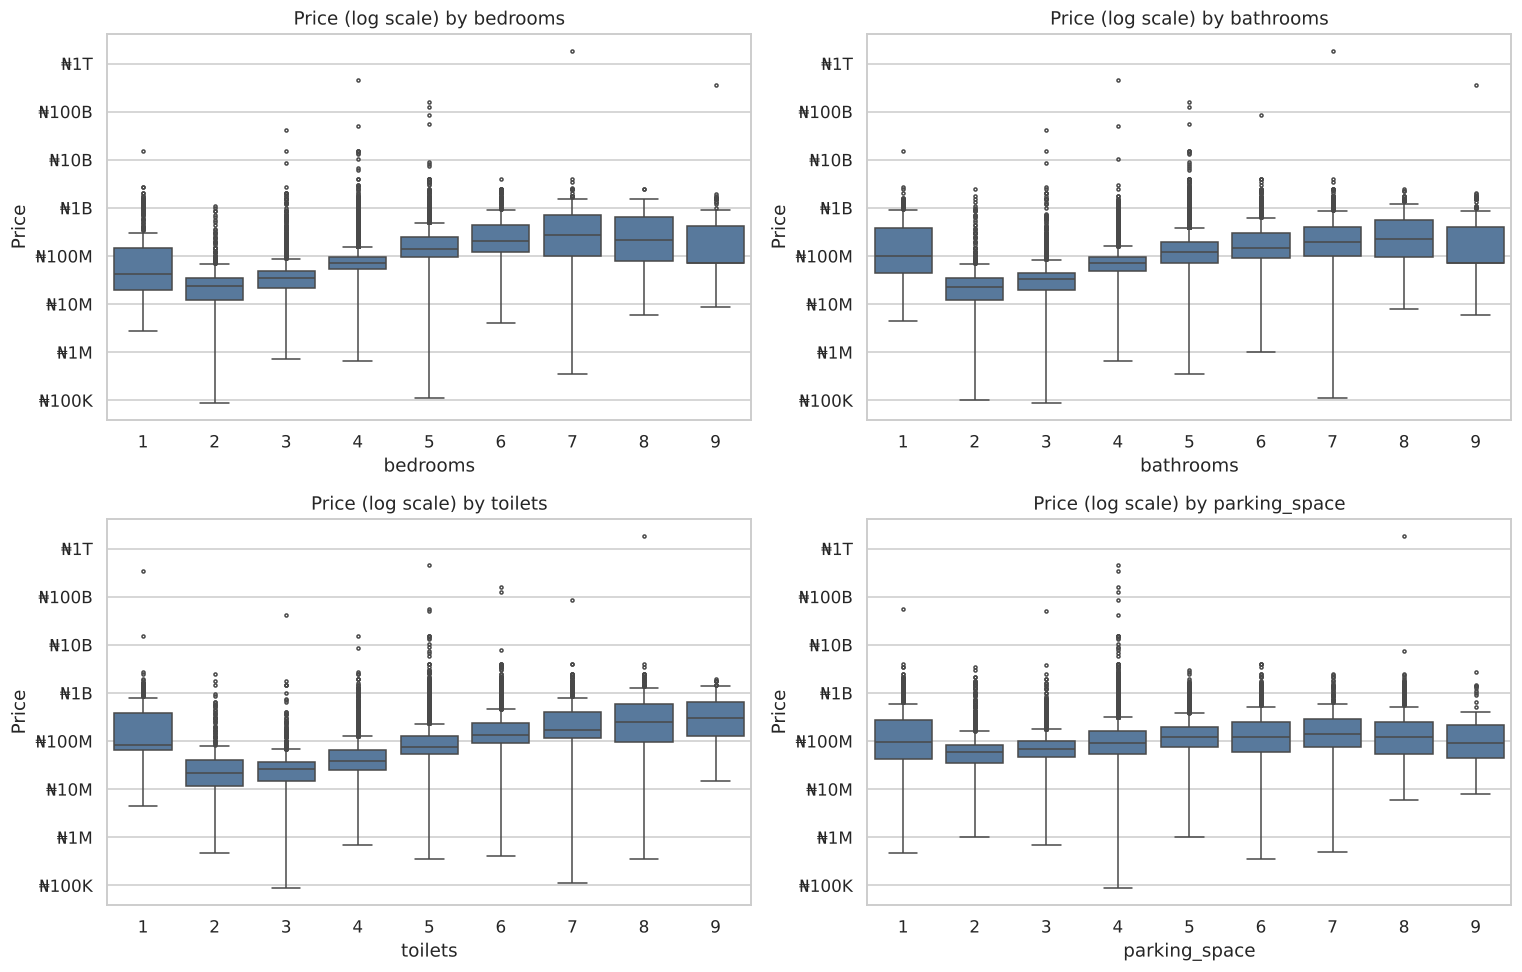

**Finding.** Spearman correlations with price run from 0.19 to 0.61, strongest for bedrooms. Pearson against raw price reaches only 0.026 because a few huge prices dominate; against log price it runs from 0.14 to 0.52. Bedrooms, bathrooms and toilets correlate with one another at 0.75 to 0.78 (Spearman).

**Decision.** Judge the features on log price or rank correlations, not raw Pearson. Their effect probably depends on location and type (Task 13), and the three room counts overlap, so expect redundancy at the feature-selection stage.

In [14]:
log_price = np.log10(df_raw["price"])
rows = []
for c in NUM_COLS:
    rows.append({
        "feature": c,
        "pearson_vs_price": df_raw[c].corr(df_raw["price"]),
        "pearson_vs_log_price": df_raw[c].corr(log_price),
        "spearman_vs_price": df_raw[c].corr(df_raw["price"], method="spearman"),
    })
corr = pd.DataFrame(rows).set_index("feature").round(3)
md("**Correlation with price**")
display(corr)
md("**Correlation among the features (Spearman)**")
display(df_raw[NUM_COLS].corr(method="spearman").round(2))

med = pd.concat({c: df_raw.groupby(c)["price"].median() for c in NUM_COLS}, axis=1)
med.index = med.index.astype(int)
med.index.name = "value"
md("**Median price by feature value**")
show(med, money=list(med.columns))

plot_df = df_raw.assign(**{c: df_raw[c].astype(int) for c in NUM_COLS})
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), NUM_COLS):
    sns.boxplot(data=plot_df, x=col, y="price", color="#4C78A8", ax=ax, fliersize=2)
    ax.set_yscale("log")
    naira_axis(ax, "y")
    ax.set_title(f"Price (log scale) by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Price")
plt.tight_layout()
plt.show()

best = corr["spearman_vs_price"].idxmax()
room_corr = df_raw[["bedrooms", "bathrooms", "toilets"]].corr(method="spearman").to_numpy()
room_off_diag = room_corr[~np.eye(3, dtype=bool)]
md(f"""**Finding.** Spearman correlations with price run from {corr['spearman_vs_price'].min():.2f} to {corr['spearman_vs_price'].max():.2f}, strongest for {best}. Pearson against raw price reaches only {corr['pearson_vs_price'].abs().max():.3f} because a few huge prices dominate; against log price it runs from {corr['pearson_vs_log_price'].min():.2f} to {corr['pearson_vs_log_price'].max():.2f}. Bedrooms, bathrooms and toilets correlate with one another at {room_off_diag.min():.2f} to {room_off_diag.max():.2f} (Spearman).

**Decision.** Judge the features on log price or rank correlations, not raw Pearson. Their effect probably depends on location and type (Task 13), and the three room counts overlap, so expect redundancy at the feature-selection stage.""")

## Task 13: Property type and location together
**Purpose.** Check whether location effects differ by property type, and how much price varies between towns of the same state and type.
**Method.** Median price by type for Lagos and Abuja, and the highest-priced town-and-type combinations with at least 20 listings. Dot plots are used because bars on a log axis have no meaningful baseline.

**Median price by property type, Lagos vs Abuja**

state,Abuja,Lagos
title,,
Detached Bungalow,₦35.0M,₦25.0M
Semi Detached Bungalow,₦25.0M,₦26.0M
Terraced Bungalow,₦24.1M,₦33.2M
Block of Flats,₦45.0M,₦45.0M
Terraced Duplexes,₦65.0M,₦60.0M
Semi Detached Duplex,₦80.0M,₦70.0M
Detached Duplex,₦170.0M,₦130.0M


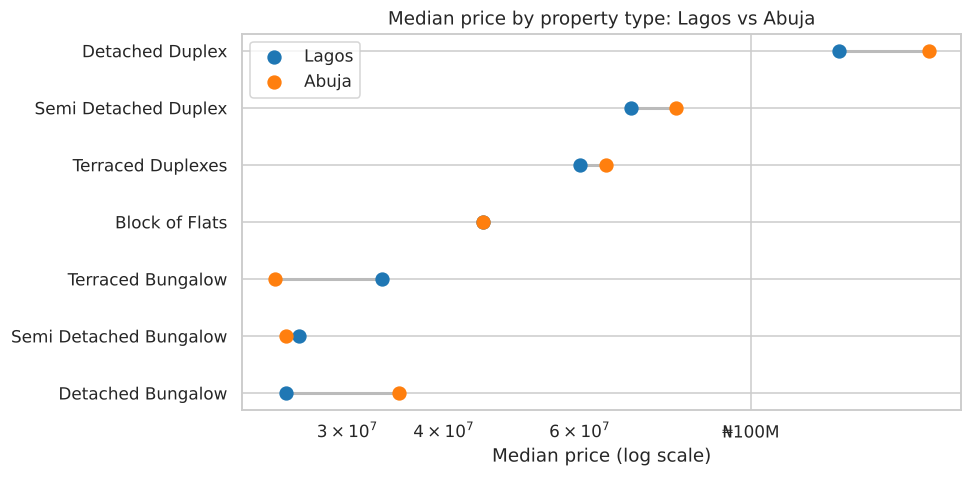

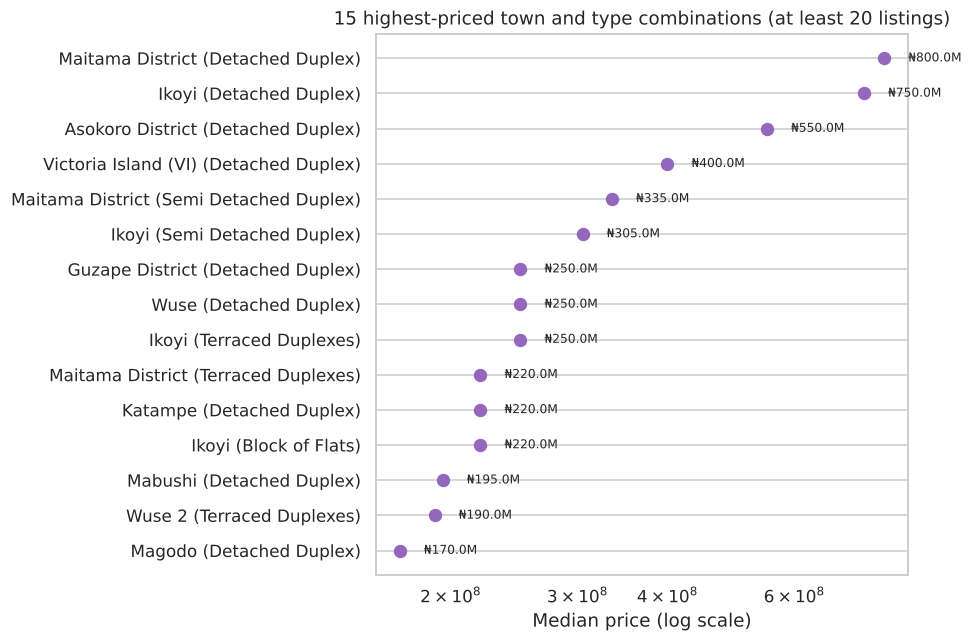

**Finding.** Abuja has the higher median for 4 of 7 property types and Lagos for the rest, so the state effect is not uniform across types. The median detached duplex in Lagos ranges from ₦30.0M in Ifako-Ijaiye to ₦750.0M in Ikoyi. Groups below 20 listings were left out of the ranking because their medians are unreliable.

**Decision.** Town, state and type should all be model inputs. Models must be able to capture interactions (tree-based models do this naturally; linear models need interaction terms).

In [15]:
la = (df_raw[df_raw["state"].isin(["Lagos", "Abuja"])]
      .groupby(["title", "state"])["price"].agg(rows="count", median="median").reset_index())
piv = la.pivot(index="title", columns="state", values="median").sort_values("Lagos")
md("**Median price by property type, Lagos vs Abuja**")
show(piv, money=list(piv.columns))

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(piv))
ax.hlines(y, piv.min(axis=1), piv.max(axis=1), color="#bbbbbb", lw=2, zorder=1)
ax.scatter(piv["Lagos"], y, s=70, color="tab:blue", label="Lagos", zorder=2)
ax.scatter(piv["Abuja"], y, s=70, color="tab:orange", label="Abuja", zorder=2)
ax.set_yticks(y)
ax.set_yticklabels(piv.index)
ax.set_xscale("log")
naira_axis(ax, "x")
ax.set_xlabel("Median price (log scale)")
ax.set_title("Median price by property type: Lagos vs Abuja")
ax.legend()
plt.tight_layout()
plt.show()

tt = (df_raw.groupby(["town", "state", "title"])["price"].agg(rows="count", median="median").reset_index())
tt = tt[tt["rows"] >= 20].sort_values("median", ascending=False)
top15 = tt.head(15).copy()
top15["label"] = top15["town"] + " (" + top15["title"] + ")"
top15 = top15.iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(top15["median"], np.arange(len(top15)), s=60, color="tab:purple")
for i, v in enumerate(top15["median"]):
    ax.text(v * 1.08, i, naira(v), va="center", fontsize=8)
ax.set_yticks(np.arange(len(top15)))
ax.set_yticklabels(top15["label"])
ax.set_xscale("log")
naira_axis(ax, "x")
ax.set_xlabel("Median price (log scale)")
ax.set_title("15 highest-priced town and type combinations (at least 20 listings)")
plt.tight_layout()
plt.show()

dd = tt[(tt["state"] == "Lagos") & (tt["title"] == "Detached Duplex")].sort_values("median")
if len(dd) >= 2:
    lo, hi = dd.iloc[0], dd.iloc[-1]
    range_txt = (f"The median detached duplex in Lagos ranges from {naira(lo['median'])} in {lo['town']} "
                 f"to {naira(hi['median'])} in {hi['town']}.")
else:
    range_txt = ""
n_abuja_higher = int((piv["Abuja"] > piv["Lagos"]).sum())
md(f"""**Finding.** Abuja has the higher median for {n_abuja_higher} of {len(piv)} property types and Lagos for the rest, so the state effect is not uniform across types. {range_txt} Groups below 20 listings were left out of the ranking because their medians are unreliable.

**Decision.** Town, state and type should all be model inputs. Models must be able to capture interactions (tree-based models do this naturally; linear models need interaction terms).""")

## Exploration summary and decisions

| Issue found | Where | Decision | Handled in |
|---|---|---|---|
| Exact duplicate rows, concentrated in Lagos | Tasks 3, 4 | Remove after labels are fixed; document as an assumption | Task 16 |
| "Anambara" label on towns from other states | Tasks 8, 11 | Reassign using documented evidence; exclude the unresolved row | Task 15 |
| Implausible prices (far from comparable listings) | Task 5 | Compare with the median of comparable listings in the **training** data; remove records more than 10 times above or below it | Task 18 |
| Strong right skew in price | Task 5 | Model log price | Task 21 |
| Geographic concentration in Lagos and Abuja | Tasks 6, 8 | Document as a limitation | Task 30 |
| Many towns with very few listings | Tasks 6, 9 | Pool rare towns; report error by data volume | Tasks 21, 26 |
| Bedrooms, bathrooms and toilets overlap | Task 12 | Expect redundancy; keep all and check importance | Task 27 |
| No property size, age or condition | Task 2 | Document as a limit on achievable accuracy | Tasks 22, 30 |

# Part 2: Data cleaning
Order of operations: **labels, then exact duplicates, then the split, then the price rule.**
- Labels come first because mislabelled rows hide duplicates and distort town-level price references.
- Duplicates are removed before the split so that no identical listing can sit on both sides of it.
- The price rule comes after the split because its reference medians are computed from the **training data only**; the test set never influences what is kept or removed.

## Task 14: Create the working copy
**Purpose.** Keep one untouched original and do all changes on a copy, with an audit trail.
**Method.** `df = df_raw.copy()`; keep the original state in `state_original`; add an `exclude_reason` column. Rows are never deleted from `df`. Each later step records *why* a row is left out of modelling, so nothing is lost.

In [16]:
df = df_raw.copy()
df["state_original"] = df["state"]
df["exclude_reason"] = ""
assert len(df) == len(df_raw)
print(f"Working copy ready: {len(df):,} rows. Original kept in df_raw ({len(df_raw):,} rows).")

Working copy ready: 24,326 rows. Original kept in df_raw (24,326 rows).


## Task 15: Fix the "Anambara" state labels
**Purpose.** Remove a systematic labelling error before anything else uses `state`.
**Method.** (1) Gather evidence that the label is wrong: exact twins under other states, and the majority state of each town elsewhere in the data. (2) Reassign using an explicit, reviewed town-to-state table. (3) For any town not in the table, fall back to its majority state, only if that majority is overwhelming. (4) Anything unresolved is excluded from modelling, not guessed.

In [17]:
WRONG_LABEL = "Anambara"

# Reviewed mapping: the towns whose Anambara-labelled rows are reassigned.
TOWN_TO_STATE = {
    # Lagos
    "Lekki": "Lagos", "Ibeju Lekki": "Lagos", "Ajah": "Lagos", "Alimosho": "Lagos", "Ikoyi": "Lagos",
    "Ifako-Ijaiye": "Lagos", "Ikorodu": "Lagos", "Ikeja": "Lagos", "Victoria Island (VI)": "Lagos",
    "Ketu": "Lagos", "Ikotun": "Lagos", "Gbagada": "Lagos", "Agege": "Lagos", "Ojo": "Lagos",
    "Shomolu": "Lagos", "Yaba": "Lagos",
    # Abuja
    "Lokogoma District": "Abuja", "Guzape District": "Abuja", "Mbora (Nbora)": "Abuja",
    "Gwarinpa": "Abuja", "Katampe": "Abuja", "Jabi": "Abuja",
    # Ogun
    "Mowe Ofada": "Ogun", "Mowe Town": "Ogun", "Arepo": "Ogun", "Magboro": "Ogun",
    # Other states
    "Port Harcourt": "Rivers", "Ibadan": "Oyo", "Owerri Municipal": "Imo", "Akure": "Ondo",
}
# Never altered by this step. Its Lagos/Ogun ambiguity is recorded as a limitation instead.
NO_TOUCH_TOWNS = {"Isheri North"}
# Anambara-labelled rows in these towns are never reassigned, by table or by majority. Karu: the data cannot
# say whether it is Abuja or Nasarawa, so the row is excluded from modelling instead of guessed.
ALWAYS_EXCLUDE_TOWNS = {"Karu"}
FALLBACK_MIN_ROWS = 5      # a town needs at least this many correctly labelled rows ...
FALLBACK_MIN_SHARE = 0.9   # ... and at least this share of them in one state to be auto-assigned

In [18]:
# Evidence 1: exact twins. Do Anambara rows have an identical listing under another state?
anam = df[df["state"] == WRONG_LABEL]
match_cols = [c for c in KEY_COLS if c != "state"]
others = df.loc[df["state"] != WRONG_LABEL, match_cols + ["state"]].drop_duplicates()
anam_rows = anam[match_cols].rename_axis("row").reset_index()
matches = anam_rows.merge(others, on=match_cols, how="inner")
n_anam = len(anam)
n_matched = int(matches["row"].nunique())
single_state = int((matches.groupby("row")["state"].nunique() == 1).sum())

# Evidence 2: geography. Where do the same towns sit when they are labelled correctly?
non_bad = df[df["state"] != WRONG_LABEL]
town_states = non_bad.groupby(["town", "state"]).size().rename("rows_elsewhere").reset_index()
town_states["share"] = town_states["rows_elsewhere"] / town_states.groupby("town")["rows_elsewhere"].transform("sum")
top_state_by_town = (town_states.sort_values(["town", "rows_elsewhere"], ascending=[True, False])
                     .drop_duplicates("town").set_index("town"))
ev = (anam.groupby("town").size().rename("rows_labelled_Anambara").to_frame()
      .join(top_state_by_town[["state", "rows_elsewhere", "share"]]
            .rename(columns={"state": "majority_state_elsewhere"})))
ev["share"] = (ev["share"] * 100).round(1)
ev["planned_state"] = ev.index.map(TOWN_TO_STATE)
ev["agrees_with_majority"] = ev["planned_state"] == ev["majority_state_elsewhere"]
ev = ev.sort_values("rows_labelled_Anambara", ascending=False)
md("**Evidence by town: where each Anambara-labelled town sits elsewhere in the data**")
display(ev)

n_agree = int(ev["agrees_with_majority"].sum())
exceptions = ev.index[~ev["agrees_with_majority"]].tolist()
md(f"""**Finding.** {n_matched} of {n_anam} Anambara-labelled rows ({n_matched / n_anam:.0%}) have an exact twin (same bedrooms, bathrooms, toilets, parking, type, town and price) under another state, and {single_state} of those twins sit in a single state. For {n_agree} of {len(ev)} towns the planned state equals the town's majority state elsewhere in the data. Towns that need a manual look because they are not backed by the majority rule: {exceptions}.""")

**Evidence by town: where each Anambara-labelled town sits elsewhere in the data**

,rows_labelled_Anambara,majority_state_elsewhere,rows_elsewhere,share,planned_state,agrees_with_majority
town,,,,,,
Lekki,54,Lagos,10841.0,100.0,Lagos,True
Ajah,22,Lagos,2142.0,100.0,Lagos,True
Ibeju Lekki,11,Lagos,492.0,100.0,Lagos,True
Mowe Ofada,6,Ogun,174.0,100.0,Ogun,True
Ikoyi,6,Lagos,1541.0,100.0,Lagos,True
Ikorodu,5,Lagos,236.0,100.0,Lagos,True
Alimosho,4,Lagos,142.0,100.0,Lagos,True
Lokogoma District,4,Abuja,217.0,100.0,Abuja,True
Port Harcourt,3,Rivers,432.0,100.0,Rivers,True


**Finding.** 128 of 145 Anambara-labelled rows (88%) have an exact twin (same bedrooms, bathrooms, toilets, parking, type, town and price) under another state, and 128 of those twins sit in a single state. For 29 of 31 towns the planned state equals the town's majority state elsewhere in the data. Towns that need a manual look because they are not backed by the majority rule: ['Akure', 'Karu'].

In [19]:
def clean_labels(df, town_to_state=TOWN_TO_STATE, no_touch=NO_TOUCH_TOWNS, always_exclude=ALWAYS_EXCLUDE_TOWNS,
                 wrong_label=WRONG_LABEL, fallback_min_rows=FALLBACK_MIN_ROWS,
                 fallback_min_share=FALLBACK_MIN_SHARE):
    """Reassign rows labelled with `wrong_label` to their real state. Returns a new frame."""
    out = df.copy()
    if "state_original" not in out.columns:
        out["state_original"] = out["state"]
    if "exclude_reason" not in out.columns:
        out["exclude_reason"] = ""
    out["label_fix"] = "unchanged"

    bad = out["state"].eq(wrong_label)
    town = out["town"]

    # Rule 1: reviewed town -> state table.
    planned = town.map(town_to_state)
    skip = town.isin(no_touch) | town.isin(always_exclude)   # towns this step must not reassign
    rule = bad & planned.notna() & ~skip
    out.loc[rule, "state"] = planned[rule]
    out.loc[rule, "label_fix"] = "mapped_rule"

    # Rule 2: majority state of the same town among correctly labelled rows.
    elsewhere = out.loc[~bad].groupby(["town", "state"]).size().rename("n").reset_index()
    elsewhere["total"] = elsewhere.groupby("town")["n"].transform("sum")
    elsewhere = (elsewhere.sort_values(["town", "n"], ascending=[True, False])
                 .drop_duplicates("town").set_index("town"))
    maj_state = town.map(elsewhere["state"])
    maj_share = town.map(elsewhere["n"] / elsewhere["total"])
    maj_total = town.map(elsewhere["total"])
    fallback = (bad & ~rule & ~skip & maj_state.notna()
                & (maj_share >= fallback_min_share) & (maj_total >= fallback_min_rows))
    out.loc[fallback, "state"] = maj_state[fallback]
    out.loc[fallback, "label_fix"] = "mapped_majority"

    # Anything still unresolved is kept in the table but excluded from modelling.
    unresolved = bad & ~rule & ~fallback
    out.loc[unresolved, "label_fix"] = "unresolved"
    out.loc[unresolved & out["exclude_reason"].eq(""), "exclude_reason"] = "unresolved_state"
    return out


df = clean_labels(df)

md("**Outcome of the label fix**")
display(df["label_fix"].value_counts().rename_axis("label_fix").to_frame("rows"))

mapped = df[df["label_fix"].str.startswith("mapped")]
md("**Where the reassigned rows went**")
display(mapped["state"].value_counts().rename_axis("state").to_frame("rows"))

fallback_rows = df[df["label_fix"] == "mapped_majority"]
if len(fallback_rows):
    md("**Reassigned by the majority rule (not in the reviewed table). Please confirm these.**")
    display(fallback_rows.groupby(["town", "state"]).size().rename("rows").reset_index())

remaining = df[df["state"] == WRONG_LABEL]
md("**Rows still labelled Anambara (excluded from modelling)**")
show(remaining[["town", "state", "title", "bedrooms", "price", "exclude_reason"]], money=["price"])
assert (remaining["exclude_reason"] != "").all(), "an Anambara row would reach the model"

**Outcome of the label fix**

,rows
label_fix,
unchanged,24181
mapped_rule,144
unresolved,1


**Where the reassigned rows went**

,rows
state,
Lagos,118
Abuja,10
Ogun,9
Rivers,3
Ondo,2
Oyo,1
Imo,1


**Rows still labelled Anambara (excluded from modelling)**

,town,state,title,bedrooms,price,exclude_reason
8547,Karu,Anambara,Semi Detached Bungalow,2.0,₦9.5M,unresolved_state


**Decision.**
1. Reassign Anambara rows using the reviewed town table `TOWN_TO_STATE` (towns confirmed by the exact-twin and majority evidence above, plus Akure to Ondo). **Check this table against your own findings before relying on it.**
2. Towns not in the table are reassigned only if one state holds at least 90% of that town's correctly labelled rows (minimum 5 rows). Each such case is listed above for confirmation.
3. **Karu** (`ALWAYS_EXCLUDE_TOWNS`) is never reassigned, even by the majority rule. The data does not show whether it is in Abuja or Nasarawa, so the Anambara-labelled Karu row is excluded from modelling and stays in the audit table.
4. **Isheri North** is never touched. It appears under Lagos in the data, but the town sits close to the Lagos/Ogun boundary. This is recorded as a limitation.
5. The original label is preserved in `state_original` for traceability.

## Task 16: Remove exact duplicate listings
**Purpose.** Prevent identical rows from appearing in both the training and the test set, which would make test scores look better than they are.
**Method.** Among the rows still eligible, keep the first occurrence of each identical listing (same bedrooms, bathrooms, toilets, parking, type, town, corrected state and price) and mark the rest `is_duplicate`. This runs *after* the label correction, so repeats hidden by wrong state labels are found too.
**Assumption.** The data has no listing ID, size or date, so we cannot prove that repeats are scraping duplicates rather than genuinely identical units. We accept this to protect the evaluation.

In [20]:
def deduplicate(df, key_cols=KEY_COLS):
    '''Mark repeated listings (keep the first) and exclude them from modelling. Returns a new frame.'''
    out = df.copy()
    if "exclude_reason" not in out.columns:
        out["exclude_reason"] = ""
    eligible = out["exclude_reason"].eq("")
    is_dup = pd.Series(False, index=out.index)
    is_dup.loc[eligible] = out.loc[eligible].duplicated(subset=list(key_cols), keep="first")
    out["is_duplicate"] = is_dup
    out.loc[is_dup, "exclude_reason"] = "duplicate"
    return out


dups_on_raw = int(df_raw.duplicated().sum())
dups_after_fix = int(df.duplicated(subset=KEY_COLS).sum())

df = deduplicate(df)
n_dup = int(df["exclude_reason"].eq("duplicate").sum())

assert not df.loc[df["exclude_reason"] == "", :].duplicated(subset=KEY_COLS).any(), "duplicates remain"
md(f'''**Finding.** {n_dup:,} repeated listings are marked as duplicates and excluded. A duplicate check on the raw file would have found {dups_on_raw:,} repeats; after the label correction the same check finds {dups_after_fix:,}, so correcting labels first exposes {dups_after_fix - dups_on_raw:,} extra repeats that would otherwise have slipped through.

**Decision.** Keep one copy of each listing. The removed rows stay in the audit table `df` with `exclude_reason = "duplicate"`.''')

**Finding.** 10,561 repeated listings are marked as duplicates and excluded. A duplicate check on the raw file would have found 10,438 repeats; after the label correction the same check finds 10,561, so correcting labels first exposes 123 extra repeats that would otherwise have slipped through.

**Decision.** Keep one copy of each listing. The removed rows stay in the audit table `df` with `exclude_reason = "duplicate"`.

## Task 17: Split into training and test sets
**Purpose.** Hold out data for one honest final evaluation.
**Method.** A random 80/20 split of the rows that are still eligible, stratified by region (Lagos, Abuja, Other) so the smaller states appear on both sides. The split is recorded in a `split` column of the audit table. A check confirms that no identical listing sits on both sides.
**Limitation.** Listings that share every input but differ in price may fall on both sides. The model cannot tell them apart anyway, so the test score describes performance on listings *similar to ones it has seen* (see Limitations, Task 30).

In [21]:
TEST_SIZE = 0.2


def split_data(df, test_size=TEST_SIZE, random_state=RANDOM_STATE):
    '''Random split of the eligible rows, stratified by region. Adds a `split` column ("train", "test" or "").'''
    out = df.copy()
    out["split"] = ""
    ids = out.index[out["exclude_reason"].eq("")]
    states = out.loc[ids, "state"]
    region = np.where(states.isin(["Lagos", "Abuja"]), states, "Other")
    train_ids, test_ids = train_test_split(ids, test_size=test_size, random_state=random_state, stratify=region)
    out.loc[train_ids, "split"] = "train"
    out.loc[test_ids, "split"] = "test"
    return out


df = split_data(df)

split_check = pd.DataFrame({
    name: {"rows": int((df["split"] == name).sum()),
           "median_price": df.loc[df["split"] == name, "price"].median(),
           "Lagos_%": (df.loc[df["split"] == name, "state"] == "Lagos").mean() * 100,
           "Abuja_%": (df.loc[df["split"] == name, "state"] == "Abuja").mean() * 100}
    for name in ["train", "test"]}).T
split_check["rows"] = split_check["rows"].astype(int)
show(split_check, money=["median_price"], pct=["Lagos_%", "Abuja_%"])

overlap = df[df["split"] == "train"].merge(df[df["split"] == "test"], on=KEY_COLS, how="inner")
assert len(overlap) == 0, f"{len(overlap)} identical listings appear in both train and test"
md(f'''**Finding.** {int((df["split"] == "train").sum()):,} training and {int((df["split"] == "test").sum()):,} test listings before the price rule. No identical listing appears on both sides, and the state mix and median price are close.

**Decision.** Use this split. The test set is not touched again until Task 25.''')

,rows,median_price,Lagos_%,Abuja_%
train,11011,₦75.0M,62.4%,22.7%
test,2753,₦75.0M,62.4%,22.7%


**Finding.** 11,011 training and 2,753 test listings before the price rule. No identical listing appears on both sides, and the state mix and median price are close.

**Decision.** Use this split. The test set is not touched again until Task 25.

## Task 18: Remove implausible prices (comparable-property rule)
**Purpose.** Remove prices that cannot be right for that kind of property in that place, without one global cut-off. A ₦660K price is impossible for a detached duplex in Ikoyi (median around ₦750M) but possible for a small bungalow in Mowe.
**Method.**
1. For every group of comparable listings (same town, state and property type; if that group has fewer than 10 listings, the same state and type; failing that, the type alone), take the **median price of the training rows only**.
2. A record is flagged if its price is **more than 10 times above, or below one tenth of,** its group's median (`PRICE_MAX_RATIO = 10`). This is deliberately looser than a 4× rule: luxury and very small properties legitimately sit well away from the median, and only extreme values should go.
3. Flagged records are **removed from modelling** (training and test alike) but kept in the audit table with the reason `implausible_price`.

The reference is computed from training data only, so the test set cannot influence the rule. The sensitivity table shows how many records other limits would remove.

... showing 15 of 197 rows


**Sensitivity: how many records each rule would remove**

,removed from train,removed from test,% of eligible rows
rule (times the median),,,
4x,553,149,5.1%
10x <- used,158,39,1.4%
18x,84,20,0.8%
32x,58,15,0.5%
100x,27,8,0.3%


**Which comparison group each record was checked against**

,records
reference group used,
town+state+title,12157
state+title,1431
title,176


**Removed records, most extreme first**

,town,state,title,bedrooms,price,price_ref_median,times the median,split
2385,Maitama District,Abuja,Semi Detached Duplex,5.0,₦110.0K,₦350.0M,"1/3,182",train
15962,Lekki,Lagos,Detached Duplex,9.0,₦350.0B,₦140.0M,"2,500x",train
4096,Ikoyi,Lagos,Detached Duplex,7.0,₦1.8T,₦800.0M,"2,250x",train
15806,Ifako-Ijaiye,Lagos,Detached Duplex,5.0,₦55.0B,₦30.0M,"1,833x",test
7098,Lekki,Lagos,Semi Detached Duplex,5.0,₦125.0B,₦75.0M,"1,667x",test
6632,Ikoyi,Lagos,Semi Detached Duplex,4.0,₦450.0B,₦320.0M,"1,406x",train
4327,Lekki,Lagos,Detached Duplex,5.0,₦160.0B,₦140.0M,"1,143x",train
2449,Asokoro District,Abuja,Detached Duplex,2.0,₦462.8K,₦524.4M,"1/1,133",train
15836,Guzape District,Abuja,Terraced Duplexes,5.0,₦85.0B,₦85.0M,"1,000x",train
6724,Ikoyi,Lagos,Detached Duplex,3.0,₦1.0M,₦800.0M,1/800,train


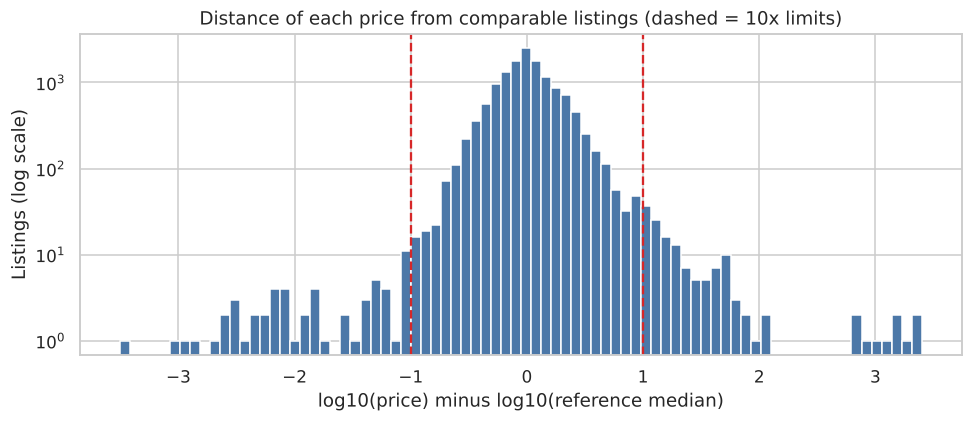

**Finding.** 197 records are more than 10 times away from their comparable-listing median (59 far too low, 138 far too high); 158 are in the training side and 39 in the test side. That is 1.4% of the eligible rows. A 4x rule would have removed 5.1% (see the table).

**Decision.**
- Remove the flagged records from modelling and keep them in the audit table (`price_flag`, `price_dev_log10`, `price_ref_median`).
- The reference medians come from the training rows only.
- **Consequence for evaluation:** the model is trained and tested on prices within 10 times of comparable listings. Its scores describe that retained range, not the extreme prices that were removed.
- Limitation: with no size column, a very large property can legitimately cost far more than its group's median; the removed "too high" records are worth a manual glance.

In [22]:
PRICE_MAX_RATIO = 10.0   # remove prices more than 10x above, or below 1/10 of, the comparable-listing median
MIN_GROUP = 10           # minimum listings for a group to serve as a reference
REFERENCE_LEVELS = [["town", "state", "title"], ["state", "title"], ["title"]]


def build_price_reference(train_rows, levels=REFERENCE_LEVELS, min_group=MIN_GROUP):
    '''Median log10 price of each comparable-listing group, from the TRAINING rows only.'''
    tables = []
    for lvl in levels:
        g = (train_rows.assign(_lp=np.log10(train_rows["price"]))
             .groupby(lvl)["_lp"].agg(["median", "size"]).reset_index())
        g = g[g["size"] >= min_group].rename(columns={"median": "_ref"})[lvl + ["_ref"]]
        tables.append((lvl, g))
    return tables


def price_deviation(df, reference):
    '''log10(price) minus log10(reference median), using the most specific group available.'''
    ref = np.full(len(df), np.nan)
    used = np.array([""] * len(df), dtype=object)
    for lvl, g in reference:
        r = df[lvl].merge(g, on=lvl, how="left")["_ref"].to_numpy(dtype=float)
        take = np.isnan(ref) & ~np.isnan(r)
        ref[take] = r[take]
        used[take] = "+".join(lvl)
    return pd.DataFrame({"price_ref_median": 10 ** ref, "price_ref_level": used,
                         "price_dev_log10": np.log10(df["price"].to_numpy()) - ref}, index=df.index)


def flag_prices(df, reference, max_ratio=PRICE_MAX_RATIO):
    '''Flag eligible rows priced more than `max_ratio` times above or below their reference. Returns a new frame.'''
    out = df.copy()
    dev = price_deviation(out, reference)
    out = out.drop(columns=dev.columns, errors="ignore").join(dev)
    limit = np.log10(max_ratio)
    eligible = out["exclude_reason"].eq("")
    low = (out["price_dev_log10"] <= -limit) & eligible
    high = (out["price_dev_log10"] >= limit) & eligible
    out["price_flag"] = low | high
    out["price_flag_dir"] = np.where(low, "too_low", np.where(high, "too_high", ""))
    out.loc[out["price_flag"], "exclude_reason"] = "implausible_price"
    return out


reference = build_price_reference(df[df["split"] == "train"])
dev_all = price_deviation(df, reference)
elig = df["exclude_reason"].eq("")

rows = []
for r in [4, 10, 18, 32, 100]:
    lim = np.log10(r)
    hit = (dev_all["price_dev_log10"].abs() >= lim) & elig
    rows.append({"rule (times the median)": f"{r}x" + ("  <- used" if r == PRICE_MAX_RATIO else ""),
                 "removed from train": int((hit & (df["split"] == "train")).sum()),
                 "removed from test": int((hit & (df["split"] == "test")).sum()),
                 "% of eligible rows": hit.sum() / elig.sum() * 100})
sens = pd.DataFrame(rows).set_index("rule (times the median)")
md("**Sensitivity: how many records each rule would remove**")
show(sens, pct=["% of eligible rows"])

df = flag_prices(df, reference)

level_use = df.loc[elig, "price_ref_level"].replace("", "no reference").value_counts().rename_axis("reference group used").to_frame("records")
md("**Which comparison group each record was checked against**")
display(level_use)

flagged = df[df["exclude_reason"] == "implausible_price"].copy()
flagged["abs_dev"] = flagged["price_dev_log10"].abs()
flagged = flagged.sort_values("abs_dev", ascending=False)
flagged["times the median"] = (10 ** flagged["price_dev_log10"]).map(lambda v: f"{v:,.0f}x" if v >= 1 else f"1/{1 / v:,.0f}")
md("**Removed records, most extreme first**")
show(flagged[["town", "state", "title", "bedrooms", "price", "price_ref_median", "times the median", "split"]],
     money=["price", "price_ref_median"], max_rows=15)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(dev_all.loc[elig, "price_dev_log10"].dropna(), bins=80, color="#4C78A8")
ax.set_yscale("log")
for t in (-np.log10(PRICE_MAX_RATIO), np.log10(PRICE_MAX_RATIO)):
    ax.axvline(t, color="tab:red", ls="--")
ax.set_xlabel("log10(price) minus log10(reference median)")
ax.set_ylabel("Listings (log scale)")
ax.set_title(f"Distance of each price from comparable listings (dashed = {PRICE_MAX_RATIO:.0f}x limits)")
plt.tight_layout()
plt.show()

n_low = int((flagged["price_flag_dir"] == "too_low").sum())
n_high = int((flagged["price_flag_dir"] == "too_high").sum())
md(f'''**Finding.** {len(flagged):,} records are more than {PRICE_MAX_RATIO:.0f} times away from their comparable-listing median ({n_low:,} far too low, {n_high:,} far too high); {int((flagged["split"] == "train").sum()):,} are in the training side and {int((flagged["split"] == "test").sum()):,} in the test side. That is {len(flagged) / elig.sum():.1%} of the eligible rows. A 4x rule would have removed {sens.iloc[0, 2]:.1f}% (see the table).

**Decision.**
- Remove the flagged records from modelling and keep them in the audit table (`price_flag`, `price_dev_log10`, `price_ref_median`).
- The reference medians come from the training rows only.
- **Consequence for evaluation:** the model is trained and tested on prices within {PRICE_MAX_RATIO:.0f} times of comparable listings. Its scores describe that retained range, not the extreme prices that were removed.
- Limitation: with no size column, a very large property can legitimately cost far more than its group's median; the removed "too high" records are worth a manual glance.''')

## Task 19: Summarise what was removed and what was retained
**Purpose.** Show exactly how the raw file became the modelling data, so the cleaning can be audited.
**Method.** Compare the data after each step, list where every raw row ended up, and save the training set, the test set and the full audit table.

In [23]:
def model_frame(prepared, key_cols=KEY_COLS):
    '''The rows that go to modelling: kept rows, model columns plus the split (original row numbers preserved).'''
    kept = prepared.loc[prepared["exclude_reason"].eq(""), list(key_cols) + ["split"]]
    return kept


mf = model_frame(df)
train = mf[mf["split"] == "train"].drop(columns="split")
test = mf[mf["split"] == "test"].drop(columns="split")
assert len(train.merge(test, on=KEY_COLS)) == 0, "identical listings appear in both train and test"


def stage_summary(frames):
    rows = []
    for name, f in frames.items():
        rows.append({"stage": name, "rows": len(f), "min_price": f["price"].min(), "median_price": f["price"].median(),
                     "mean_price": f["price"].mean(), "max_price": f["price"].max(),
                     "Lagos_%": (f["state"] == "Lagos").mean() * 100, "Abuja_%": (f["state"] == "Abuja").mean() * 100})
    return pd.DataFrame(rows).set_index("stage")


reason = df["exclude_reason"]
stages = {
    "0. Raw file": df_raw,
    "1. After label correction": df[reason != "unresolved_state"],
    "2. After removing duplicates": df[~reason.isin(["unresolved_state", "duplicate"])],
    "3. After price rule (modelling data)": df[reason == ""],
}
md("**Before and after each cleaning step**")
stages_tbl = stage_summary(stages)
show(stages_tbl, money=["min_price", "median_price", "mean_price", "max_price"], pct=["Lagos_%", "Abuja_%"])

md("**Where every raw row ended up**")
waterfall = reason.replace("", "kept for modelling").value_counts().rename_axis("outcome").to_frame("rows")
waterfall["% of raw rows"] = (waterfall["rows"] / len(df_raw) * 100).round(1)
display(waterfall)

OUT_DIR = Path("data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)
train.to_csv(OUT_DIR / "train.csv", index=False)
test.to_csv(OUT_DIR / "test.csv", index=False)
df.to_csv(OUT_DIR / "audit_all_rows.csv", index=False)

n_kept = len(train) + len(test)
RETAINED_MIN, RETAINED_MAX = float(mf["price"].min()), float(mf["price"].max())
md(f'''**Finding.** {len(df_raw):,} raw rows become {n_kept:,} modelling rows ({n_kept / len(df_raw):.1%}): {len(train):,} for training and {len(test):,} for testing. Removed: {int((reason == "unresolved_state").sum()):,} with an unresolvable state, {int((reason == "duplicate").sum()):,} exact duplicates and {int((reason == "implausible_price").sum()):,} implausible prices. De-duplication is the largest step and mostly removes Lagos repeats (Lagos share {stages_tbl.iloc[1]['Lagos_%']:.0f}% to {stages_tbl.iloc[2]['Lagos_%']:.0f}%, median price {naira(stages_tbl.iloc[1]['median_price'])} to {naira(stages_tbl.iloc[2]['median_price'])}); the price rule removes few rows but brings the mean price from {naira(stages_tbl.iloc[2]['mean_price'])} to {naira(stages_tbl.iloc[3]['mean_price'])}. **Retained price range: {naira(RETAINED_MIN)} to {naira(RETAINED_MAX)}.**

**Decision.** Use `train` and `test` as the modelling data. Files saved in `{OUT_DIR}`: `train.csv`, `test.csv` and `audit_all_rows.csv` (every raw row with its flags, split and exclusion reason).''')

**Before and after each cleaning step**

,rows,min_price,median_price,mean_price,max_price,Lagos_%,Abuja_%
stage,,,,,,,
0. Raw file,24326,₦90.0K,₦85.0M,₦301.4M,₦1.8T,75.8%,14.5%
1. After label correction,24325,₦90.0K,₦85.0M,₦301.4M,₦1.8T,76.3%,14.5%
2. After removing duplicates,13764,₦90.0K,₦75.0M,₦402.9M,₦1.8T,62.4%,22.7%
3. After price rule (modelling data),13567,₦1.5M,₦75.0M,₦158.2M,₦7.5B,62.5%,22.5%


**Where every raw row ended up**

,rows,% of raw rows
outcome,,
kept for modelling,13567,55.8
duplicate,10561,43.4
implausible_price,197,0.8
unresolved_state,1,0.0


**Finding.** 24,326 raw rows become 13,567 modelling rows (55.8%): 10,853 for training and 2,714 for testing. Removed: 1 with an unresolvable state, 10,561 exact duplicates and 197 implausible prices. De-duplication is the largest step and mostly removes Lagos repeats (Lagos share 76% to 62%, median price ₦85.0M to ₦75.0M); the price rule removes few rows but brings the mean price from ₦402.9M to ₦158.2M. **Retained price range: ₦1.5M to ₦7.5B.**

**Decision.** Use `train` and `test` as the modelling data. Files saved in `data/processed`: `train.csv`, `test.csv` and `audit_all_rows.csv` (every raw row with its flags, split and exclusion reason).

## Task 20: Package the cleaning as reusable code
**Purpose.** The Streamlit app and any rerun must apply exactly the same logic as this notebook.
**Method.** Chain the steps in `prepare_dataset()`, write all the constants and functions to `data_prep.py`, then re-import that module and check that it reproduces the notebook's audit table exactly. The app itself only needs the cleaned list of valid states and towns (`locations.csv`), because duplicate and price removal are training-time steps.

In [24]:
def prepare_dataset(raw):
    '''Label correction, de-duplication, split and price rule on a raw frame. Returns the full audit table.'''
    out = raw.copy()
    out["state_original"] = out["state"]
    out["exclude_reason"] = ""
    out = clean_labels(out)
    out = deduplicate(out)
    out = split_data(out)
    reference = build_price_reference(out[out["split"] == "train"])
    return flag_prices(out, reference)


MODULE_PATH = Path("data_prep.py")
CONSTANT_NAMES = ["KEY_COLS", "RANDOM_STATE", "TEST_SIZE", "WRONG_LABEL", "TOWN_TO_STATE", "NO_TOUCH_TOWNS", "ALWAYS_EXCLUDE_TOWNS",
                  "FALLBACK_MIN_ROWS", "FALLBACK_MIN_SHARE", "PRICE_MAX_RATIO", "MIN_GROUP", "REFERENCE_LEVELS"]
FUNCTIONS = [clean_labels, deduplicate, split_data, build_price_reference, price_deviation, flag_prices,
             prepare_dataset, model_frame]

parts = ["# data_prep.py - generated from the notebook (Task 20). Edit the notebook, then regenerate.",
         "import numpy as np", "import pandas as pd", "from sklearn.model_selection import train_test_split", ""]
for name in CONSTANT_NAMES:
    parts.append(f"{name} = {pprint.pformat(globals()[name], sort_dicts=False)}")
parts.append("")
for fn in FUNCTIONS:
    parts += [inspect.getsource(fn), ""]
MODULE_PATH.write_text("\n".join(parts), encoding="utf-8")

# Prove the module reproduces the notebook exactly.
import importlib
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
import data_prep
importlib.reload(data_prep)
rebuilt = data_prep.prepare_dataset(df_raw)
pd.testing.assert_frame_equal(rebuilt, df)
pd.testing.assert_frame_equal(data_prep.model_frame(rebuilt), mf)
print(f"{MODULE_PATH} written. Its output matches the notebook: {len(rebuilt):,} rows, {int(rebuilt['exclude_reason'].eq('').sum()):,} kept for modelling.")

locations = mf[["state", "town"]].drop_duplicates().sort_values(["state", "town"]).reset_index(drop=True)
locations.to_csv(OUT_DIR / "locations.csv", index=False)
print(f"{OUT_DIR / 'locations.csv'} written: {len(locations)} valid state-town pairs for the app's dropdowns.")

data_prep.py written. Its output matches the notebook: 24,326 rows, 13,567 kept for modelling.
data/processed/locations.csv written: 188 valid state-town pairs for the app's dropdowns.


# Part 3: Feature preparation
Part 2 produced clean, leakage-free training and test sets. Parts 3 to 6 turn them into a deployed model.

| | |
|---|---|
| **Target** | Asking price in Naira, modelled on the log scale. |
| **Evaluation rule** | All choices (features, model, tuning) are made with cross-validation on the **training** set. The **test** set is used once, in Task 25, for reporting. |
| **Outputs** | `models/model.joblib`, `models/model_meta.json`, `house_features.py`, `predictor.py`, `app.py`, `tests/`, `requirements.txt`, `reports/results.md` and figures in `reports/figures/`. |

In [25]:
import json
import subprocess
import platform
import time
from datetime import date

import joblib
import sklearn
from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV, KFold, RandomizedSearchCV, cross_validate

MODEL_DIR = Path("models")
FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
t_start = time.time()


def evaluate(y_true, pred_ln):
    """Regression metrics. `pred_ln` is the model's ln(price) prediction; y_true is the price in Naira."""
    y_true = np.asarray(y_true, dtype=float)
    pred = np.exp(pred_ln)
    ln_true = np.log(y_true)
    err = np.asarray(pred_ln) - ln_true
    ape = np.abs(pred - y_true) / y_true
    return {
        "R2 (log price)": r2_score(ln_true, pred_ln),
        "RMSE (log)": float(np.sqrt(np.mean(err ** 2))),
        "MAE (log)": float(np.mean(np.abs(err))),
        "Median error %": float(np.median(ape) * 100),
        "Within 30%": float(np.mean(ape <= 0.30) * 100),
        "MAE (₦)": float(np.mean(np.abs(pred - y_true))),
        "RMSE (₦)": float(np.sqrt(np.mean((pred - y_true) ** 2))),
    }


def fit_model(est, X, y_ln):
    return clone(est).fit(X, y_ln)

## Task 21: Prepare the modelling inputs and features
**Purpose.** Turn the seven inputs into model features without using anything a user of the app would not have.
**Method.** `house_features.py` is written first, because the saved model refers to it and the app imports it. Its `add_features` derives `town_state` (town and state together, since the same town name can appear in two states), `rooms_total`, `bath_per_bed` and `toilet_per_bed`. Categories seen fewer than 5 times in training are pooled into one "infrequent" level, so a town unseen at prediction time causes no error. Three pipeline styles are provided: one-hot encoding with scaling for linear models, one-hot for random forests, and native categorical handling for gradient boosting. The module also holds the lookup baseline (median log price of comparable training listings).

In [26]:
# house_features.py: feature engineering, model pipelines and the lookup baseline
Path("house_features.py").write_text(r'''"""Feature engineering and model building blocks shared by the training notebook and the Streamlit app.

The saved model pickles references to functions and classes in this module, so the module must be
importable (kept next to the app) both when training and when serving.
"""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler

# Columns a user (or the app) must supply.
NUM_INPUTS = ["bedrooms", "bathrooms", "toilets", "parking_space"]
CAT_INPUTS = ["title", "town", "state"]
RAW_COLS = NUM_INPUTS + CAT_INPUTS

# Columns the model actually sees.
ENGINEERED = ["rooms_total", "bath_per_bed", "toilet_per_bed"]
MODEL_NUM_COLS = NUM_INPUTS + ENGINEERED
MODEL_CAT_COLS = ["title", "state", "town_state"]

MIN_CAT_COUNT = 5   # categories seen fewer times than this are pooled into one "infrequent" level


def region_of(state):
    """Group states into the three regions used for stratification and error analysis."""
    return state if state in ("Lagos", "Abuja") else "Other"


def region_series(states):
    return pd.Series(states).map(region_of).to_numpy()


def add_features(X):
    """Raw listing columns -> model columns. Works on a DataFrame with at least RAW_COLS."""
    X = pd.DataFrame(X).copy()
    for c in NUM_INPUTS:
        X[c] = X[c].astype(float)
    X["town_state"] = X["town"].astype(str) + " | " + X["state"].astype(str)
    X["rooms_total"] = X["bedrooms"] + X["bathrooms"] + X["toilets"]
    X["bath_per_bed"] = X["bathrooms"] / X["bedrooms"].clip(lower=1)
    X["toilet_per_bed"] = X["toilets"] / X["bedrooms"].clip(lower=1)
    return X[MODEL_NUM_COLS + MODEL_CAT_COLS]


class GroupMedianBaseline(RegressorMixin, BaseEstimator):
    """Simple lookup baseline: median log price of comparable training listings.

    Tries town+type, then state+type, then type alone; a group needs `min_group` listings to be used.
    """

    LEVELS = (("town_state", "title"), ("state", "title"), ("title",))

    def __init__(self, min_group=5):
        self.min_group = min_group

    def fit(self, X, y):
        d = pd.DataFrame(X).copy()
        d["_y"] = np.asarray(y, dtype=float)
        self.tables_ = []
        for level in self.LEVELS:
            g = d.groupby(list(level))["_y"].agg(["median", "size"])
            g = g[g["size"] >= self.min_group]
            self.tables_.append(g["median"].to_dict())
        self.global_ = float(d["_y"].median())
        return self

    def predict(self, X):
        d = pd.DataFrame(X)
        out = np.full(len(d), np.nan)
        for level, table in zip(self.LEVELS, self.tables_):
            keys = list(zip(*[d[c] for c in level])) if len(level) > 1 else list(d[level[0]])
            vals = np.array([table.get(k, np.nan) for k in keys], dtype=float)
            take = np.isnan(out) & ~np.isnan(vals)
            out[take] = vals[take]
        out[np.isnan(out)] = self.global_
        return out


def _preprocessor(kind):
    if kind == "onehot_scaled":      # linear models
        num = StandardScaler()
    else:
        num = "passthrough"
    if kind == "native":             # tree models with native categorical support
        cat = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                             encoded_missing_value=np.nan, min_frequency=MIN_CAT_COUNT)
    else:
        cat = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=MIN_CAT_COUNT,
                            sparse_output=False)
    return ColumnTransformer([("num", num, MODEL_NUM_COLS), ("cat", cat, MODEL_CAT_COLS)])


def native_categorical_mask():
    """Mask for HistGradientBoostingRegressor(categorical_features=...) after the 'native' preprocessor."""
    return [False] * len(MODEL_NUM_COLS) + [True] * len(MODEL_CAT_COLS)


def build_pipeline(model, kind="onehot"):
    """features -> preprocessing -> model. `kind` is 'onehot', 'onehot_scaled' or 'native'.
    Input is a DataFrame with RAW_COLS; the model predicts ln(price)."""
    steps = [("features", FunctionTransformer(add_features))]
    if kind != "none":
        steps.append(("prep", _preprocessor(kind)))
    steps.append(("model", model))
    return Pipeline(steps)
''', encoding="utf-8")
print("written: house_features.py")

written: house_features.py


In [27]:
import importlib

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
import house_features as hf
importlib.reload(hf)

train = train.reset_index(drop=True)   # Task 19 keeps the original row numbers; modelling works by position
test = test.reset_index(drop=True)
assert set(KEY_COLS) <= set(train.columns) and set(KEY_COLS) <= set(test.columns)
assert train[KEY_COLS].notna().all().all() and test[KEY_COLS].notna().all().all()

X_train, X_test = train[hf.RAW_COLS].copy(), test[hf.RAW_COLS].copy()
y_train_ln, y_test_ln = np.log(train["price"].to_numpy()), np.log(test["price"].to_numpy())

display(hf.add_features(X_train.head(3)))
n_levels = X_train.assign(town_state=X_train["town"] + " | " + X_train["state"]).nunique()[["title", "state", "town_state"]]
show(n_levels.to_frame("distinct levels"))
assert n_levels["town_state"] < 255, "HistGradientBoosting supports at most 255 levels per categorical feature"
md(f'''**Finding.** {len(train):,} training and {len(test):,} test listings, no missing values. The model sees {len(hf.MODEL_NUM_COLS)} numeric and {len(hf.MODEL_CAT_COLS)} categorical features; `town_state` has {int(n_levels['town_state'])} levels in training.

**Decision.** Use these features for every candidate model. The target is `ln(price)` because prices are strongly right-skewed (Task 5); predictions are converted back to Naira with `exp`.''')

,bedrooms,bathrooms,toilets,parking_space,rooms_total,bath_per_bed,toilet_per_bed,title,state,town_state
0,6.0,5.0,5.0,4.0,16.0,0.833333,0.833333,Detached Duplex,Abuja,Mabushi | Abuja
1,4.0,5.0,5.0,4.0,14.0,1.250000,1.250000,Detached Duplex,Lagos,Lekki | Lagos
2,4.0,4.0,5.0,6.0,13.0,1.000000,1.250000,Detached Duplex,Lagos,Ajah | Lagos


,distinct levels
title,7
state,24
town_state,178


**Finding.** 10,853 training and 2,714 test listings, no missing values. The model sees 7 numeric and 3 categorical features; `town_state` has 178 levels in training.

**Decision.** Use these features for every candidate model. The target is `ln(price)` because prices are strongly right-skewed (Task 5); predictions are converted back to Naira with `exp`.

## Task 22: Estimate the accuracy ceiling
**Purpose.** The dataset has no property size, age or condition. Before comparing models, estimate how much of the price variation these inputs can possibly explain, so the final scores are judged against a realistic ceiling rather than a perfect score.
**Method.** Group training listings that have *identical* inputs (same state, town, type, bedrooms, bathrooms, toilets and parking). Their price differences cannot be explained by any model that sees only those inputs. Measure the pooled spread of log price inside such groups.

In [28]:
def pooled_within_group(df):
    '''Pooled standard deviation of ln(price) among listings with identical inputs.'''
    d = df[hf.RAW_COLS + ["price"]].copy()
    d["ln"] = np.log(d["price"])
    g = d.groupby(hf.RAW_COLS)
    d["n"] = g["ln"].transform("size")
    d = d[d["n"] >= 2]
    ss = float(((d["ln"] - d.groupby(hf.RAW_COLS)["ln"].transform("mean")) ** 2).sum())
    n_groups = d.groupby(hf.RAW_COLS).ngroups
    return float(np.sqrt(ss / (len(d) - n_groups))), len(d), n_groups


sd_within, rows_in_groups, n_groups = pooled_within_group(train)
total_sd = float(np.std(y_train_ln))
ceiling_r2 = 1 - (sd_within / total_sd) ** 2
display(pd.DataFrame({"listings in repeated-input groups": [rows_in_groups], "groups": [n_groups],
                      "within-group SD (log)": [sd_within], "typical price spread": [f"x{np.exp(sd_within):.2f}"],
                      "approx. best possible R2": [ceiling_r2]}, index=["training set"]).round(3))
md(f'''**Finding.** Listings with identical inputs still differ in price by a typical factor of about {np.exp(sd_within):.2f} (one standard deviation). If a model captured everything these inputs can explain, R2 on log price would top out near {ceiling_r2:.2f}. This is an approximation based on the {rows_in_groups:,} listings that share inputs with another.

**Decision.** Treat this as the realistic ceiling. A model that approaches it is doing what these inputs allow; further gains need new information, above all property size.''')

,listings in repeated-input groups,groups,within-group SD (log),typical price spread,approx. best possible R2
training set,6940,1475,0.513,x1.67,0.793


**Finding.** Listings with identical inputs still differ in price by a typical factor of about 1.67 (one standard deviation). If a model captured everything these inputs can explain, R2 on log price would top out near 0.79. This is an approximation based on the 6,940 listings that share inputs with another.

**Decision.** Treat this as the realistic ceiling. A model that approaches it is doing what these inputs allow; further gains need new information, above all property size.

# Part 4: Model development
Baselines, candidate models, cross-validation and selection. Only the training set is used here.

## Task 23: Compare baselines and candidate models with cross-validation
**Purpose.** Find out which kind of model suits this data, and whether machine learning beats simple rules.
**Method.** 5-fold cross-validation on the training set, scored on log-price error. Two baselines: a **global median** (the same price for every listing) and a **grouped median** (median price of the same town and property type, falling back to state and type, then type). Candidates: Ridge regression, Random Forest and Histogram Gradient Boosting with default-style settings.

In [29]:
candidates = {
    "Median only": hf.build_pipeline(DummyRegressor(strategy="median"), kind="none"),
    "Town + type median lookup": hf.build_pipeline(hf.GroupMedianBaseline(), kind="none"),
    "Ridge": hf.build_pipeline(Ridge(alpha=1.0), kind="onehot_scaled"),
    "Random Forest": hf.build_pipeline(
        RandomForestRegressor(n_estimators=150, min_samples_leaf=2, max_features=0.5, n_jobs=-1,
                              random_state=RANDOM_STATE), kind="onehot"),
    "Gradient Boosting": hf.build_pipeline(
        HistGradientBoostingRegressor(categorical_features=hf.native_categorical_mask(), random_state=RANDOM_STATE),
        kind="native"),
}
SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}


def cv_row(est):
    r = cross_validate(est, X_train, y_train_ln, cv=CV, scoring=SCORING, n_jobs=1)
    return {"CV RMSE (log)": -r["test_rmse"].mean(), "CV RMSE std": r["test_rmse"].std(),
            "CV MAE (log)": -r["test_mae"].mean(), "CV R2 (log)": r["test_r2"].mean(),
            "fit time (s)": r["fit_time"].mean()}


cv_table = pd.DataFrame({name: cv_row(est) for name, est in candidates.items()}).T.sort_values("CV RMSE (log)")
display(cv_table.round(3))

best_default = cv_table.index[0]
gain_vs_lookup = 1 - cv_table.loc["Gradient Boosting", "CV RMSE (log)"] / cv_table.loc["Town + type median lookup", "CV RMSE (log)"]
md(f"""**Finding.** Lowest cross-validated error among the defaults: **{best_default}** (RMSE {cv_table.iloc[0, 0]:.3f} on log price, a typical error factor of about x{np.exp(cv_table.iloc[0, 0]):.2f}). Gradient Boosting's error is {gain_vs_lookup:.0%} {'lower' if gain_vs_lookup > 0 else 'higher'} than the simple town-and-type lookup.

**Decision.** Tune the strongest model families (Ridge, Random Forest, Gradient Boosting) in Task 24. The two baselines stay in the final comparison so the value of machine learning is judged against simple rules.""")

,CV RMSE (log),CV RMSE std,CV MAE (log),CV R2 (log),fit time (s)
Gradient Boosting,0.554,0.014,0.417,0.758,0.282
Random Forest,0.575,0.017,0.434,0.740,1.716
Ridge,0.589,0.011,0.450,0.727,0.039
Town + type median lookup,0.622,0.011,0.468,0.695,0.016
Median only,1.129,0.015,0.878,-0.003,0.009


**Finding.** Lowest cross-validated error among the defaults: **Gradient Boosting** (RMSE 0.554 on log price, a typical error factor of about x1.74). Gradient Boosting's error is 11% lower than the simple town-and-type lookup.

**Decision.** Tune the strongest model families (Ridge, Random Forest, Gradient Boosting) in Task 24. The two baselines stay in the final comparison so the value of machine learning is judged against simple rules.

## Task 24: Tune the strongest models and select one
**Purpose.** Give each serious candidate a fair chance with good settings, then choose one.
**Method.** Cross-validated search on the training set only: grid search for Ridge, randomised search for the two tree ensembles (scored by RMSE on log price). The lowest cross-validated error decides the winner. The Random Forest search can take several minutes.

,best CV RMSE (log),search time (s),best settings
Ridge,0.588907,2.230243,{'alpha': 1}
Random Forest,0.581005,58.366971,"{'n_estimators': 250, 'min_samples_leaf': 3, '..."
Gradient Boosting,0.551636,39.894271,"{'l2_regularization': 10.0, 'learning_rate': 0..."


,CV RMSE (log),CV RMSE std,CV MAE (log),CV R2 (log),fit time (s)
Gradient Boosting (tuned),0.552,0.013,0.416,0.761,0.901
Random Forest (tuned),0.574,0.015,0.434,0.740,2.767
Ridge (tuned),0.589,0.011,0.450,0.727,0.048
Town + type median lookup,0.622,0.011,0.468,0.695,0.016
Median only,1.129,0.015,0.878,-0.003,0.009


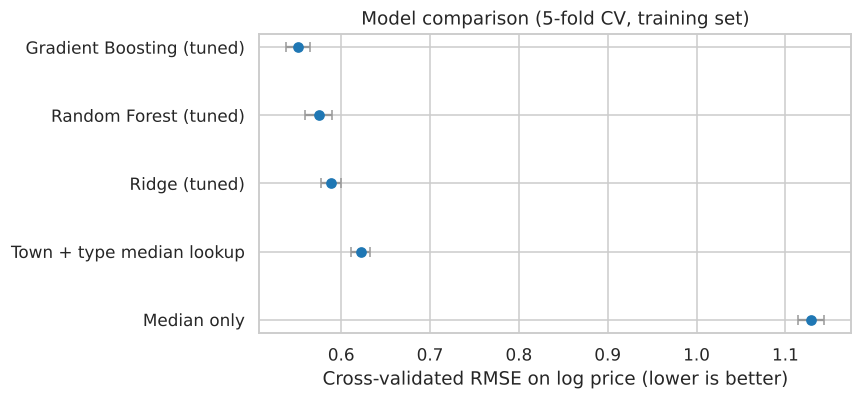

**Finding.** The best model by cross-validation is **Gradient Boosting** (RMSE 0.552; runner-up Random Forest (tuned) at 0.574). The gap to the town-and-type lookup is 11%.

**Decision.** Select Gradient Boosting. This choice was made on training data only.

In [30]:
search_specs = {
    "Ridge": (GridSearchCV, candidates["Ridge"],
              {"model__alpha": [0.1, 0.3, 1, 3, 10, 30, 100]}, {}),
    "Random Forest": (RandomizedSearchCV, candidates["Random Forest"],
                      {"model__n_estimators": [150, 250, 400], "model__max_depth": [None, 12, 20, 30],
                       "model__min_samples_leaf": [1, 2, 3, 5], "model__max_features": [0.3, 0.5, 0.8]},
                      {"n_iter": 8}),
    "Gradient Boosting": (RandomizedSearchCV, candidates["Gradient Boosting"],
                          {"model__learning_rate": loguniform(0.03, 0.3), "model__max_iter": [200, 400, 700],
                           "model__max_leaf_nodes": [15, 31, 63], "model__min_samples_leaf": [10, 20, 40, 80],
                           "model__l2_regularization": [0.0, 0.1, 1.0, 10.0], "model__max_depth": [None, 6, 10]},
                          {"n_iter": 20}),
}
tuned, tuning_rows = {}, {}
for name, (Search, est, grid, extra) in search_specs.items():
    t0 = time.time()
    kwargs = dict(cv=3 if name == "Random Forest" else CV, scoring="neg_root_mean_squared_error", n_jobs=-1, refit=True)
    if Search is RandomizedSearchCV:
        kwargs["random_state"] = RANDOM_STATE
    search = Search(est, grid, **kwargs, **extra)
    search.fit(X_train, y_train_ln)
    tuned[name] = search.best_estimator_
    tuning_rows[name] = {"best CV RMSE (log)": -search.best_score_, "search time (s)": time.time() - t0,
                         "best settings": {k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v)
                                           for k, v in search.best_params_.items()}}
tuning = pd.DataFrame(tuning_rows).T
display(tuning)

# Re-score every finalist with the same 5-fold split so the numbers are comparable.
final_cv = pd.DataFrame({
    "Median only": cv_table.loc["Median only"],
    "Town + type median lookup": cv_table.loc["Town + type median lookup"],
    **{f"{name} (tuned)": pd.Series(cv_row(est)) for name, est in tuned.items()},
}).T.sort_values("CV RMSE (log)")
display(final_cv.round(3))

SELECTED = final_cv.index[0].replace(" (tuned)", "")
assert SELECTED in tuned, "a baseline won: the machine-learning models add nothing over simple rules"

fig, ax = plt.subplots(figsize=(8, 3.8))
order = final_cv.index[::-1]
ax.errorbar(final_cv.loc[order, "CV RMSE (log)"], range(len(order)), xerr=final_cv.loc[order, "CV RMSE std"],
            fmt="o", color="tab:blue", ecolor="#999999", capsize=3)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_xlabel("Cross-validated RMSE on log price (lower is better)")
ax.set_title("Model comparison (5-fold CV, training set)")
plt.tight_layout()
plt.savefig(FIG_DIR / "model_comparison.png", dpi=150)
plt.show()

runner_up = final_cv.index[1]
md(f"""**Finding.** The best model by cross-validation is **{SELECTED}** (RMSE {final_cv.iloc[0, 0]:.3f}; runner-up {runner_up} at {final_cv.iloc[1, 0]:.3f}). The gap to the town-and-type lookup is {1 - final_cv.iloc[0, 0] / final_cv.loc['Town + type median lookup', 'CV RMSE (log)']:.0%}.

**Decision.** Select {SELECTED}. This choice was made on training data only.""")

# Part 5: Model evaluation
The test set is used once for performance, then only to explain where and why the model errs.

## Task 25: Evaluate the selected model on the random hold-out set
**Purpose.** Get an honest estimate of performance on listings the model has never seen.
**Method.** Fit the selected model on the full training set and predict the test set once. The two baselines are fitted on the same training data and scored on the same test set; they played no part in the selection.
**Metrics.** On the log scale (the scale the model is trained on): MAE, RMSE and R2. In plain terms: the **median percentage error** and the **share of predictions within 30%** of the actual asking price. MAE and RMSE in Naira are shown for completeness; they are dominated by a few very expensive listings.

In [31]:
final_model = fit_model(tuned[SELECTED], X_train, y_train_ln)
fitted = {"Global median": fit_model(candidates["Median only"], X_train, y_train_ln),
          "Grouped median (town + type)": fit_model(candidates["Town + type median lookup"], X_train, y_train_ln),
          f"FINAL: {SELECTED}": final_model}
test_metrics_table = pd.DataFrame({name: evaluate(test["price"], m.predict(X_test)) for name, m in fitted.items()}).T
final_pred_ln = final_model.predict(X_test)
final_metrics = evaluate(test["price"], final_pred_ln)

log_cols = ["MAE (log)", "RMSE (log)", "R2 (log price)", "Median error %", "Within 30%"]
display(test_metrics_table[log_cols].round(3))
md("**Error in Naira (dominated by a few very expensive listings)**")
display(test_metrics_table[["MAE (₦)", "RMSE (₦)"]].map(naira))
test_metrics_table.to_csv(MODEL_DIR / "test_metrics.csv")

grouped = test_metrics_table.loc["Grouped median (town + type)"]
globalm = test_metrics_table.loc["Global median"]
md(f'''**Finding.** On the random hold-out set ({len(test):,} listings) the final model reaches **R2 = {final_metrics['R2 (log price)']:.3f}** on log price, with a median error of **{final_metrics['Median error %']:.0f}%**; **{final_metrics['Within 30%']:.0f}%** of predictions fall within 30% of the actual asking price. For comparison, the grouped median reaches R2 = {grouped['R2 (log price)']:.3f} and a median error of {grouped['Median error %']:.0f}%, and the global median R2 = {globalm['R2 (log price)']:.3f}. These scores describe the **retained price range** ({naira(RETAINED_MIN)} to {naira(RETAINED_MAX)}); records removed by the price rule in Task 18 are not covered.

**Decision.** This is the performance reported for the project. No further tuning on the test set.''')

,MAE (log),RMSE (log),R2 (log price),Median error %,Within 30%
Global median,0.853,1.100,-0.001,62.772,25.092
Grouped median (town + type),0.459,0.612,0.690,34.783,44.694
FINAL: Gradient Boosting,0.404,0.539,0.759,30.505,49.410


**Error in Naira (dominated by a few very expensive listings)**

,MAE (₦),RMSE (₦)
Global median,₦112.9M,₦266.4M
Grouped median (town + type),₦69.0M,₦170.1M
FINAL: Gradient Boosting,₦61.7M,₦159.6M


**Finding.** On the random hold-out set (2,714 listings) the final model reaches **R2 = 0.759** on log price, with a median error of **31%**; **49%** of predictions fall within 30% of the actual asking price. For comparison, the grouped median reaches R2 = 0.690 and a median error of 35%, and the global median R2 = -0.001. These scores describe the **retained price range** (₦1.5M to ₦7.5B); records removed by the price rule in Task 18 are not covered.

**Decision.** This is the performance reported for the project. No further tuning on the test set.

## Task 26: Error by region and data volume
**Purpose.** Show where the model is more or less reliable, so users know when to trust the estimate.
**Method.** Break the test errors down by region (Lagos, Abuja, Other) and by how many training listings the town has, and plot predicted against actual prices. "Bias" is the mean log error: positive means the model over-predicts.

**By region**

,listings,median error %,within 30%,bias (log),RMSE (log)
region,,,,,
Lagos,1694,30.36,49.65,-0.01,0.52
Abuja,610,28.83,51.15,-0.01,0.53
Other,410,33.83,45.85,-0.01,0.62


**By how many training listings the town has**

,listings,median error %,within 30%,bias (log),RMSE (log)
volume,,,,,
under 5,48,54.87,27.08,0.17,0.95
5 to 9,31,39.28,45.16,0.01,0.55
10 to 29,154,28.33,52.60,0.01,0.53
30 or more,2481,30.36,49.70,-0.02,0.53


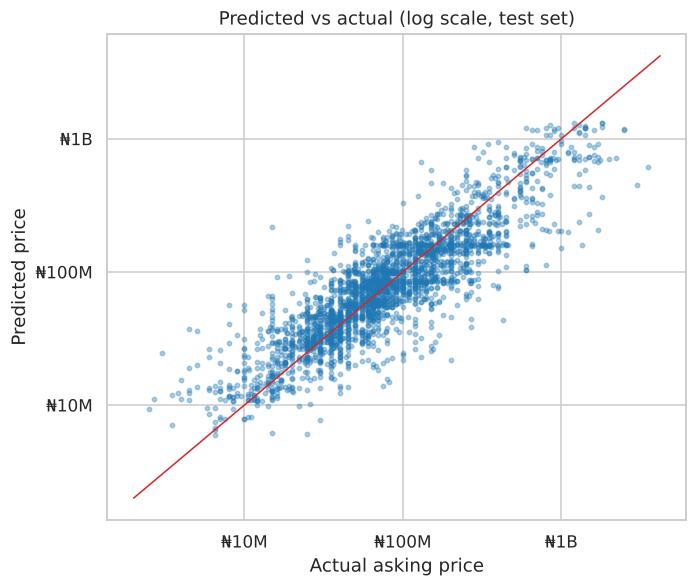

**Finding.** Median error by region: Lagos: 30% (1694 listings), Abuja: 29% (610 listings), Other: 34% (410 listings). Towns with fewer than 5 training listings (48 test listings) have a median error of 55%, against 30% for towns with 30 or more. The scatter plot shows the usual pull toward the middle for a model that cannot see property size: the dearest listings tend to be under-predicted and the cheapest over-predicted.

**Decision.** Report errors by region and data volume, and have the app warn users about towns with little training data (fewer than 10 listings) and about states outside Lagos and Abuja.

In [32]:
err = pd.DataFrame({"actual": test["price"].to_numpy(), "pred": np.exp(final_pred_ln)})
err["err_log"] = np.log(err["pred"]) - np.log(err["actual"])
err["ape"] = (err["pred"] - err["actual"]).abs() / err["actual"]
err["region"] = hf.region_series(test["state"])
town_volume = (train["town"] + " | " + train["state"]).value_counts()
err["train_listings"] = (test["town"] + " | " + test["state"]).map(town_volume).fillna(0).to_numpy()
err["volume"] = pd.cut(err["train_listings"], [-1, 4, 9, 29, np.inf], labels=["under 5", "5 to 9", "10 to 29", "30 or more"])


def breakdown(by):
    g = err.groupby(by, observed=True)
    return pd.DataFrame({"listings": g.size(), "median error %": g["ape"].median() * 100,
                         "within 30%": g["ape"].apply(lambda s: (s <= 0.3).mean() * 100),
                         "bias (log)": g["err_log"].mean(),
                         "RMSE (log)": g["err_log"].apply(lambda s: np.sqrt((s ** 2).mean()))}).round(2)


by_region = breakdown("region").reindex(["Lagos", "Abuja", "Other"]).dropna()
vol = breakdown("volume")
md("**By region**")
display(by_region)
md("**By how many training listings the town has**")
display(vol)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(err["actual"], err["pred"], s=8, alpha=0.35, color="tab:blue")
lims = [err[["actual", "pred"]].min().min() * 0.8, err[["actual", "pred"]].max().max() * 1.2]
ax.plot(lims, lims, color="tab:red", lw=1)
ax.set_xscale("log"); ax.set_yscale("log")
naira_axis(ax, "x"); naira_axis(ax, "y")
ax.set_xlabel("Actual asking price"); ax.set_ylabel("Predicted price")
ax.set_title("Predicted vs actual (log scale, test set)")
plt.tight_layout()
plt.savefig(FIG_DIR / "predicted_vs_actual.png", dpi=150)
plt.show()

region_txt = ", ".join(f"{r}: {by_region.loc[r, 'median error %']:.0f}% ({int(by_region.loc[r, 'listings'])} listings)" for r in by_region.index)
vol_txt = ""
if {"under 5", "30 or more"} <= set(vol.index):
    vol_txt = (f" Towns with fewer than 5 training listings ({int(vol.loc['under 5', 'listings'])} test listings) have a median error of "
               f"{vol.loc['under 5', 'median error %']:.0f}%, against {vol.loc['30 or more', 'median error %']:.0f}% for towns with 30 or more.")
md(f'''**Finding.** Median error by region: {region_txt}.{vol_txt} The scatter plot shows the usual pull toward the middle for a model that cannot see property size: the dearest listings tend to be under-predicted and the cheapest over-predicted.

**Decision.** Report errors by region and data volume, and have the app warn users about towns with little training data (fewer than 10 listings) and about states outside Lagos and Abuja.''')

## Task 27: Which inputs matter most?
**Purpose.** Explain the model in terms a reviewer can check against the exploration in Part 1.
**Method.** Permutation importance on the test set: shuffle one input at a time and measure how much the log-price error grows (5 repeats). A larger increase means the model relies on that input more.

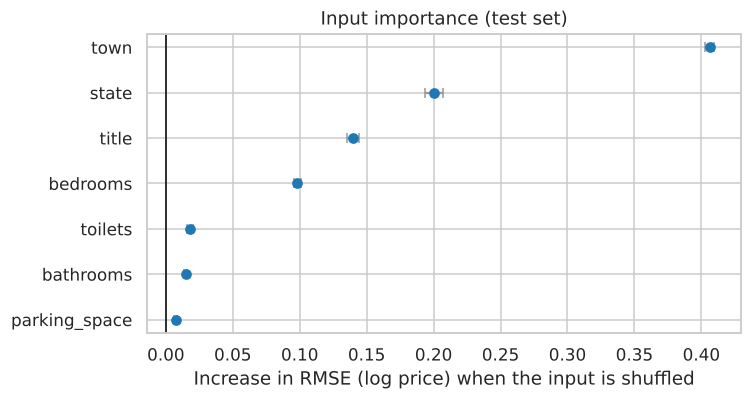

**Finding.** Shuffling `town` hurts the model most (RMSE rises by 0.406), followed by `state` and `title`; the least useful input is `parking_space` (+0.007). Room counts partly overlap (Task 12), so shuffling one understates its value when the others stay intact.

**Decision.** Keep all seven inputs: none harms the model, and the app asks for all of them.

In [33]:
perm = permutation_importance(final_model, X_test, y_test_ln, n_repeats=5, random_state=RANDOM_STATE,
                              scoring="neg_root_mean_squared_error")
imp = pd.DataFrame({"input": hf.RAW_COLS, "error increase": perm.importances_mean, "std": perm.importances_std}) \
        .sort_values("error increase")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar(imp["error increase"], range(len(imp)), xerr=imp["std"], fmt="o", color="tab:blue", ecolor="#999999", capsize=3)
ax.set_yticks(range(len(imp)))
ax.set_yticklabels(imp["input"])
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Increase in RMSE (log price) when the input is shuffled")
ax.set_title("Input importance (test set)")
plt.tight_layout()
plt.savefig(FIG_DIR / "input_importance.png", dpi=150)
plt.show()

top = imp.sort_values("error increase", ascending=False)
md(f"""**Finding.** Shuffling `{top.iloc[0]['input']}` hurts the model most (RMSE rises by {top.iloc[0]['error increase']:.3f}), followed by `{top.iloc[1]['input']}` and `{top.iloc[2]['input']}`; the least useful input is `{top.iloc[-1]['input']}` ({top.iloc[-1]['error increase']:+.3f}). Room counts partly overlap (Task 12), so shuffling one understates its value when the others stay intact.

**Decision.** Keep all seven inputs: none harms the model, and the app asks for all of them.""")

# Part 6: Deployment
The saved model, the supporting code and the Streamlit app, with checks that they behave like the model evaluated above.

## Task 28: Write the prediction code, the Streamlit app and the tests
**Purpose.** The saved model and the Streamlit app need ordinary Python files they can import. Writing them from this notebook keeps everything in one place and guarantees that the notebook, the model and the app use the same code.
**Method.** Three files are written to the project folder (`house_features.py` was written in Task 21):
- `predictor.py`: loads the model, checks the inputs against what the model was trained on, and returns a single estimated price with any warnings. It has no Streamlit dependency, so it can be tested on its own.
- `app.py`: the Streamlit interface. It offers only valid states, towns and property types, and shows the estimated asking price, a data-volume note and the measured reliability of the model.
- `tests/test_predictor.py`: unit tests for the prediction code.

In [34]:
# predictor.py: load the model, validate inputs, return an estimate
Path("predictor.py").write_text(r'''"""Load the saved model and turn user inputs into a price estimate.

This module has no Streamlit dependency, so it is easy to test. The Streamlit app (app.py) only handles the
interface and calls `predict`.
"""
import json
import math
from dataclasses import dataclass, field
from pathlib import Path

import joblib
import pandas as pd

import house_features  # noqa: F401  (must be importable so joblib can unpickle the model)
from house_features import RAW_COLS, region_of

DEFAULT_MODEL_DIR = Path(__file__).resolve().parent / "models"
THIN_TOWN_ROWS = 10        # towns with fewer training listings get a warning


def format_naira(x):
    """85_000_000 -> '₦85.0M'; 1_250_000_000 -> '₦1.25B'."""
    x = float(x)
    for limit, suffix, nd in [(1e12, "T", 2), (1e9, "B", 2), (1e6, "M", 1), (1e3, "K", 0)]:
        if abs(x) >= limit:
            return f"₦{x / limit:,.{nd}f}{suffix}"
    return f"₦{x:,.0f}"


def build_options(train):
    """Everything the app needs to know about the training data: valid inputs, ranges and data volume per town."""
    locations = (train[["state", "town"]].drop_duplicates().sort_values(["state", "town"]))
    return {
        "titles": sorted(train["title"].unique().tolist()),
        "locations": {s: sorted(g["town"].tolist()) for s, g in locations.groupby("state")},
        "ranges": {c: [int(train[c].min()), int(train[c].max())]
                   for c in ["bedrooms", "bathrooms", "toilets", "parking_space"]},
        "town_counts": (train["town"] + " | " + train["state"]).value_counts().astype(int).to_dict(),
    }


def save_bundle(model, meta, model_dir=DEFAULT_MODEL_DIR):
    model_dir = Path(model_dir)
    model_dir.mkdir(parents=True, exist_ok=True)
    joblib.dump(model, model_dir / "model.joblib", compress=3)
    (model_dir / "model_meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")


def load_bundle(model_dir=DEFAULT_MODEL_DIR):
    model_dir = Path(model_dir)
    model_path, meta_path = model_dir / "model.joblib", model_dir / "model_meta.json"
    if not model_path.exists() or not meta_path.exists():
        raise FileNotFoundError(
            f"Model files not found in {model_dir}. Run the notebook (Task 29) to create model.joblib and model_meta.json.")
    meta = json.loads(meta_path.read_text(encoding="utf-8"))
    return {"model": joblib.load(model_path), "meta": meta}


@dataclass
class Prediction:
    estimate: float
    region: str
    town_listings: int
    notes: list = field(default_factory=list)


def predict(bundle, *, state, town, title, bedrooms, bathrooms, toilets, parking_space):
    """Estimate the asking price. Raises ValueError for inputs the model was never trained on."""
    meta, model = bundle["meta"], bundle["model"]

    if title not in meta["options"]["titles"]:
        raise ValueError(f"Unknown property type: {title!r}.")
    if town not in meta["options"]["locations"].get(state, []):
        raise ValueError(f"{town!r} is not a known town in {state!r}.")
    values = {"bedrooms": bedrooms, "bathrooms": bathrooms, "toilets": toilets, "parking_space": parking_space}
    for name, v in values.items():
        lo, hi = meta["options"]["ranges"][name]
        if not (lo <= v <= hi):
            raise ValueError(f"{name} must be between {lo} and {hi} (got {v}).")

    row = pd.DataFrame([{**values, "title": title, "town": town, "state": state}])[RAW_COLS]
    ln_price = float(model.predict(row)[0])

    region = region_of(state)
    n_town = int(meta["options"]["town_counts"].get(f"{town} | {state}", 0))

    notes = []
    if n_town < THIN_TOWN_ROWS:
        notes.append(f"Only {n_town} listings in {town} were used for training, so this estimate is less reliable.")
    if region == "Other":
        notes.append("Most training listings are in Lagos and Abuja; estimates elsewhere are less reliable.")

    return Prediction(
        estimate=math.exp(ln_price),
        region=region, town_listings=n_town, notes=notes,
    )
''', encoding="utf-8")
print("written: predictor.py")

written: predictor.py


In [35]:
# app.py: Streamlit interface
Path("app.py").write_text(r'''"""Streamlit app: estimate the asking price of a residential property in Nigeria.

Run locally with:  streamlit run app.py
"""
import streamlit as st

import predictor

st.set_page_config(page_title="Nigeria House Price Estimator", page_icon="🏠", layout="centered")


@st.cache_resource(show_spinner="Loading model...")
def get_bundle():
    return predictor.load_bundle()


st.title("🏠 Nigeria House Price Estimator")
st.write("Describe a residential property to get an estimated **asking price** in Nigerian Naira (₦).")

try:
    bundle = get_bundle()
except FileNotFoundError as err:
    st.error(str(err))
    st.stop()

meta = bundle["meta"]
options = meta["options"]
ranges = options["ranges"]

st.subheader("Property details")
col_a, col_b = st.columns(2)
with col_a:
    state = st.selectbox("State", sorted(options["locations"]),
                         index=sorted(options["locations"]).index("Lagos") if "Lagos" in options["locations"] else 0)
with col_b:
    town = st.selectbox("Town / area", options["locations"][state])

title = st.selectbox("Property type", options["titles"])

c1, c2, c3, c4 = st.columns(4)
bedrooms = c1.number_input("Bedrooms", ranges["bedrooms"][0], ranges["bedrooms"][1], min(4, ranges["bedrooms"][1]), 1)
bathrooms = c2.number_input("Bathrooms", ranges["bathrooms"][0], ranges["bathrooms"][1], min(4, ranges["bathrooms"][1]), 1)
toilets = c3.number_input("Toilets", ranges["toilets"][0], ranges["toilets"][1], min(5, ranges["toilets"][1]), 1)
parking = c4.number_input("Parking spaces", ranges["parking_space"][0], ranges["parking_space"][1],
                          min(4, ranges["parking_space"][1]), 1)

if st.button("Estimate price", type="primary"):
    try:
        result = predictor.predict(bundle, state=state, town=town, title=title, bedrooms=int(bedrooms),
                                   bathrooms=int(bathrooms), toilets=int(toilets), parking_space=int(parking))
    except ValueError as err:
        st.error(f"Please check the inputs: {err}")
    else:
        st.subheader("Estimate")
        st.metric("Estimated asking price", predictor.format_naira(result.estimate))
        st.caption(f"Based on {result.town_listings:,} comparable listings in {town}.")
        for note in result.notes:
            st.warning(note)

with st.expander("How reliable is this estimate?"):
    m = meta["test_metrics"]
    st.write(
        f"The model ({meta['model']}) was trained on {meta['n_train']:,} property listings and checked on "
        f"{meta['n_test']:,} listings it had never seen. On those, the typical (median) error was about "
        f"**{m['Median error %']:.0f}%**, and **{m['Within 30%']:.0f}%** of estimates were within 30% of the "
        f"actual asking price."
    )
    st.markdown("**Limits to keep in mind**")
    for line in meta["assumptions"]:
        st.markdown(f"- {line}")

st.caption("This tool gives a rough guide based on past listings. It is not a valuation. "
           f"Model trained {meta['created']}.")
''', encoding="utf-8")
print("written: app.py")

written: app.py


In [36]:
# tests/test_predictor.py: unit tests for the prediction code
Path("tests").mkdir(exist_ok=True)
Path("tests/test_predictor.py").write_text(r'''"""Tests for the prediction code the Streamlit app relies on. Run with:  python -m pytest -q

These tests train a tiny model on made-up data, so they run in seconds and do not need the real dataset.
If models/model.joblib exists, the last test also checks the real saved model.
"""
import math
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import pytest
from sklearn.linear_model import Ridge

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
import house_features as hf  # noqa: E402
import predictor  # noqa: E402


@pytest.fixture(scope="module")
def bundle():
    rng = np.random.default_rng(0)
    towns = [("Lagos", "Lekki", 1.0), ("Lagos", "Ajah", 0.6), ("Abuja", "Gwarinpa", 0.8), ("Oyo", "Ibadan", 0.3)]
    rows = []
    for _ in range(600):
        state, town, f = towns[rng.integers(len(towns))]
        bed = int(rng.integers(2, 7))
        rows.append({"bedrooms": bed, "bathrooms": bed + 1, "toilets": bed + 1, "parking_space": int(rng.integers(1, 6)),
                     "title": str(rng.choice(["Detached Duplex", "Block of Flats"])), "town": town, "state": state,
                     "price": 2e7 * f * bed * float(np.exp(rng.normal(0, 0.3)))})
    df = pd.DataFrame(rows)
    model = hf.build_pipeline(Ridge(alpha=1.0), kind="onehot_scaled").fit(df[hf.RAW_COLS], np.log(df["price"]))
    meta = {"options": predictor.build_options(df)}
    return {"model": model, "meta": meta}


GOOD = dict(state="Lagos", town="Lekki", title="Detached Duplex", bedrooms=4, bathrooms=5, toilets=5, parking_space=3)


def test_prediction_is_a_positive_number(bundle):
    p = predictor.predict(bundle, **GOOD)
    assert math.isfinite(p.estimate) and p.estimate > 0
    assert p.region == "Lagos"


def test_other_region_gets_a_reliability_note(bundle):
    p = predictor.predict(bundle, **{**GOOD, "state": "Oyo", "town": "Ibadan"})
    assert p.region == "Other"
    assert any("Lagos and Abuja" in n for n in p.notes)


def test_more_bedrooms_costs_more_in_this_toy_model(bundle):
    small = predictor.predict(bundle, **{**GOOD, "bedrooms": 2, "bathrooms": 3, "toilets": 3}).estimate
    large = predictor.predict(bundle, **{**GOOD, "bedrooms": 6, "bathrooms": 7, "toilets": 7}).estimate
    assert large > small


@pytest.mark.parametrize("bad", [
    {"town": "Nowhere"},                      # unknown town
    {"state": "Abuja"},                       # valid town, wrong state
    {"title": "Castle"},                      # unknown property type
    {"bedrooms": 40},                         # outside the trained range
    {"parking_space": 0},                     # below the trained range
])
def test_invalid_inputs_are_rejected(bundle, bad):
    with pytest.raises(ValueError):
        predictor.predict(bundle, **{**GOOD, **bad})


def test_unseen_town_never_reaches_the_model(bundle):
    # The model can handle unseen categories, but the app only offers known towns.
    assert "Nowhere" not in bundle["meta"]["options"]["locations"]["Lagos"]


def test_format_naira():
    assert predictor.format_naira(85_000_000) == "₦85.0M"
    assert predictor.format_naira(1_250_000_000) == "₦1.25B"
    assert predictor.format_naira(660_000) == "₦660K"
    assert predictor.format_naira(500) == "₦500"


def test_group_median_baseline_falls_back_to_broader_groups():
    X = pd.DataFrame({"town_state": ["A | X"] * 6 + ["B | X"] * 2, "state": ["X"] * 8, "title": ["T"] * 8})
    y = np.array([1.0] * 6 + [5.0, 5.0])
    m = hf.GroupMedianBaseline(min_group=5).fit(X, y)
    new = pd.DataFrame({"town_state": ["A | X", "B | X", "C | Y"], "state": ["X", "X", "Y"], "title": ["T"] * 3})
    pred = m.predict(new)
    assert pred[0] == 1.0                      # town + type group is large enough
    assert pred[1] == 1.0                      # town too small -> state + type median (1.0)
    assert pred[2] == 1.0                      # unseen state -> type median


@pytest.mark.skipif(not (Path("models/model.joblib").exists() and Path("models/model_meta.json").exists()),
                    reason="saved model not found")
def test_saved_model_loads_and_predicts():
    bundle = predictor.load_bundle("models")
    meta = bundle["meta"]
    state = next(iter(meta["options"]["locations"]))
    town = meta["options"]["locations"][state][0]
    ranges = meta["options"]["ranges"]
    p = predictor.predict(bundle, state=state, town=town, title=meta["options"]["titles"][0],
                          bedrooms=ranges["bedrooms"][0], bathrooms=ranges["bathrooms"][0],
                          toilets=ranges["toilets"][0], parking_space=ranges["parking_space"][0])
    assert p.estimate > 0
''', encoding="utf-8")
print("written: tests/test_predictor.py")

written: tests/test_predictor.py


In [37]:
import predictor
importlib.reload(predictor)
print("Modules ready:", hf.__name__, predictor.__name__)

Modules ready: house_features predictor


## Task 29: Save the model and check the saved copy
**Purpose.** Package everything the Streamlit app needs and prove that the saved copy behaves like the model in memory.
**Method.** Save the fitted pipeline with `joblib` plus a metadata file (valid states and towns, input ranges, test metrics, the price rule, library versions). Then run a simplified deployment consistency check:
1. reload through `predictor.py`, the same code the app uses, and confirm the predictions equal the in-memory model's on every test row;
2. run the app's prediction function on valid inputs and confirm an invalid town is rejected;
3. run the unit tests;
4. pin the library versions used for training in `requirements.txt`.

In [38]:
meta = {
    "title": "Nigeria House Price Prediction",
    "created": date.today().isoformat(),
    "model": SELECTED,
    "target": "ln(asking price in NGN)",
    "dataset_source": DATASET_SOURCE,
    "settings": {k: (v.item() if hasattr(v, "item") else v) for k, v in tuning.loc[SELECTED, "best settings"].items()},
    "n_train": int(len(train)), "n_test": int(len(test)),
    "test_metrics": {k: round(float(v), 4) for k, v in final_metrics.items()},
    "cv_rmse_log": round(float(final_cv.loc[f"{SELECTED} (tuned)", "CV RMSE (log)"]), 4),
    "price_rule": {"max_ratio": PRICE_MAX_RATIO, "retained_price_range_ngn": [RETAINED_MIN, RETAINED_MAX],
                   "removed_records": int((df["exclude_reason"] == "implausible_price").sum())},
    "options": predictor.build_options(train),
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__, "joblib": joblib.__version__},
    "assumptions": [
        "Prices are asking prices from listings, not confirmed sale prices.",
        "Exact repeated listings were treated as duplicates and removed before training.",
        f"Records priced more than {PRICE_MAX_RATIO:.0f} times above or below comparable listings were removed, so the model is only evaluated within that price range.",
        "No property size, age or condition is available, so identical-looking properties can differ widely in price.",
        "Most training data is from Lagos and Abuja; other states are less reliable.",
    ],
}
predictor.save_bundle(final_model, meta, MODEL_DIR)

# 1. The saved copy predicts exactly like the model in memory.
bundle = predictor.load_bundle(MODEL_DIR)
reload_pred = bundle["model"].predict(X_test)
assert np.allclose(reload_pred, final_pred_ln), "the saved model gives different predictions"

# 2. The app's own prediction function: valid inputs work, an invalid one is rejected.
examples = [("Lagos", "Lekki", "Detached Duplex", 5, 5, 6, 4), ("Lagos", "Ikoyi", "Detached Duplex", 5, 6, 6, 4),
            ("Abuja", "Gwarinpa", "Terraced Duplexes", 4, 4, 5, 2), ("Oyo", "Ibadan", "Detached Bungalow", 3, 3, 4, 3)]
rows = []
for state, town, ttl, bd, ba, to, pk in examples:
    if town not in bundle["meta"]["options"]["locations"].get(state, []):
        continue
    p = predictor.predict(bundle, state=state, town=town, title=ttl, bedrooms=bd, bathrooms=ba, toilets=to, parking_space=pk)
    rows.append({"state": state, "town": town, "type": ttl, "bed": bd, "estimated price": predictor.format_naira(p.estimate),
                 "note": "; ".join(p.notes)})
display(pd.DataFrame(rows))
try:
    predictor.predict(bundle, state="Lagos", town="Not A Town", title="Detached Duplex", bedrooms=3, bathrooms=3, toilets=3, parking_space=2)
    raise AssertionError("an invalid town was accepted")
except ValueError as e:
    print("Invalid input correctly rejected:", e)

# 3. Unit tests.
res = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests"], capture_output=True, text=True, cwd=Path.cwd())
if "No module named pytest" in res.stderr:
    tests_line = "pytest is not installed here; run `pip install pytest` and then `python -m pytest -q`."
else:
    assert res.returncode == 0, res.stdout[-2000:] + res.stderr[-1000:]
    tests_line = "Unit tests: " + (res.stdout.strip().splitlines() or ["passed"])[-1]
print(tests_line)

# 4. Pin the library versions used for training, so the deployed app can load the model.
req = Path("requirements.txt")
if not req.exists():
    req.write_text("streamlit>=1.30\npandas>=2.0\nnumpy>=1.24\nscikit-learn>=1.3\njoblib>=1.3\n")
pins = {"scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__, "joblib": joblib.__version__}
lines = []
for line in req.read_text().splitlines():
    name = line.split("=")[0].split(">")[0].split("<")[0].strip().lower()
    lines.append(f"{name}=={pins[name]}" if name in pins else line)
req.write_text("\n".join(lines) + "\n")
print("requirements.txt updated with the versions used for training:", pins)

size_kb = (MODEL_DIR / "model.joblib").stat().st_size / 1024
size_note = ("" if size_kb < 90_000 else f" **Warning:** the file is {size_kb / 1024:,.0f} MB, above GitHub's 100 MB limit. "
             "Re-run Task 24 with smaller Random Forest settings or select the next-best model.")
md(f'''**Finding.** Saved `model.joblib` ({size_kb:,.0f} KB) and `model_meta.json`.{size_note} The reloaded model matches the in-memory model exactly on all {len(X_test):,} test rows, the app's prediction function accepts valid inputs and rejects an unknown town. {tests_line}

**Decision.** Deploy this model. Keep `house_features.py` and `predictor.py` in the same folder as `app.py`, and use the pinned versions in `requirements.txt`.''')

Invalid input correctly rejected: 'Not A Town' is not a known town in 'Lagos'.
Unit tests: 12 passed in 1.21s
requirements.txt updated with the versions used for training: {'scikit-learn': '1.9.1', 'numpy': '2.5.3', 'pandas': '3.0.5', 'joblib': '1.6.0'}


,state,town,type,bed,estimated price,note
0,Lagos,Lekki,Detached Duplex,5,₦160.6M,
1,Lagos,Ikoyi,Detached Duplex,5,₦759.0M,
2,Abuja,Gwarinpa,Terraced Duplexes,4,₦65.8M,
3,Oyo,Ibadan,Detached Bungalow,3,₦15.0M,Most training listings are in Lagos and Abuja;...


**Finding.** Saved `model.joblib` (341 KB) and `model_meta.json`. The reloaded model matches the in-memory model exactly on all 2,714 test rows, the app's prediction function accepts valid inputs and rejects an unknown town. Unit tests: 12 passed in 1.21s

**Decision.** Deploy this model. Keep `house_features.py` and `predictor.py` in the same folder as `app.py`, and use the pinned versions in `requirements.txt`.

# Part 7: Conclusion
## Task 30: Results, interpretation, assumptions and limitations

In [39]:
m = final_metrics
vol_limit = (f"\n- Towns with fewer than 5 training listings have a median error of {vol.loc['under 5', 'median error %']:.0f}%, "
             f"against {vol.loc['30 or more', 'median error %']:.0f}% for well-covered towns." if {"under 5", "30 or more"} <= set(vol.index) else "")
region_limit = "; ".join(f"{r} {by_region.loc[r, 'median error %']:.0f}%" for r in by_region.index)
summary_md = (f'''# Results: Nigeria House Price Prediction

### Result
- **Selected model:** {SELECTED}, chosen by 5-fold cross-validation on {len(train):,} training listings.
- **Hold-out performance** ({len(test):,} unseen listings, random split): R2 = {m['R2 (log price)']:.2f} on log price, MAE = {m['MAE (log)']:.2f} and RMSE = {m['RMSE (log)']:.2f} on the log scale, median error {m['Median error %']:.0f}%, and {m['Within 30%']:.0f}% of predictions within 30% of the actual asking price.
- **Against simple rules:** the grouped median (town + property type) reaches R2 = {grouped['R2 (log price)']:.2f} and a median error of {grouped['Median error %']:.0f}%; the global median reaches R2 = {globalm['R2 (log price)']:.2f}.
- **Ceiling:** listings with identical inputs differ in price by about x{np.exp(sd_within):.2f} (one SD), so without property size no model can reach much beyond R2 of roughly {ceiling_r2:.2f}.
- **Error by region** (median %): {region_limit}.
- **Price range covered:** {naira(RETAINED_MIN)} to {naira(RETAINED_MAX)}. {int((df['exclude_reason'] == 'implausible_price').sum()):,} records priced more than {PRICE_MAX_RATIO:.0f} times above or below comparable listings were removed; the scores apply to the retained range.

### Data preparation in one line
{len(df_raw):,} raw rows -> {len(train) + len(test):,} modelling rows: {int((df['exclude_reason'] == 'unresolved_state').sum()):,} unresolvable state, {int((df['exclude_reason'] == 'duplicate').sum()):,} exact duplicates, {int((df['exclude_reason'] == 'implausible_price').sum()):,} implausible prices removed ("Anambara" labels corrected first; price references computed from training data only).

### Assumptions
- Prices are asking prices from listings, not confirmed sale prices.
- Exact repeated listings were treated as duplicates (no listing ID, size or date exists to prove otherwise).
- "Anambara" state labels were treated as errors and reassigned from internal evidence and general geography (Task 15), not from an external reference.
- The test set is a random split of de-duplicated listings, so scores describe performance on listings *similar to ones the model has seen*.

### Limitations
- No property size, age, condition or exact address: identical-looking listings differ widely in price.
- Heavy concentration in Lagos and Abuja; other states have few listings and larger errors.{vol_limit}
- The model was not validated on towns it has never seen, so the app offers only towns present in the training data.
- Scores apply only to the retained price range; extreme prices were removed by the rule in Task 18.
- The model predicts the typical asking price for listings like the one described, not the price a buyer would pay or a valuation.
- Prices change over time and the data has no date.
- The dataset source and licence are placeholders until completed by the author.

### Next steps
Deploy `app.py` on Streamlit Community Cloud, complete the executive summary, pitch deck and video from the figures in `reports/figures/`, and (if possible) collect property size to raise the accuracy ceiling.

Notebook run time: {(time.time() - t_start) / 60:.1f} minutes.''')
Path("reports").mkdir(exist_ok=True)
Path("reports/results.md").write_text(summary_md, encoding="utf-8")
md(summary_md.split("\n", 2)[2])

**Dataset source:** [Add the dataset source link here]
**Licence / terms of use:** [Add the licence or terms of use here]

### Result
- **Selected model:** Gradient Boosting, chosen by 5-fold cross-validation on 10,853 training listings.
- **Hold-out performance** (2,714 unseen listings, random split): R2 = 0.76 on log price, MAE = 0.40 and RMSE = 0.54 on the log scale, median error 31%, and 49% of predictions within 30% of the actual asking price.
- **Against simple rules:** the grouped median (town + property type) reaches R2 = 0.69 and a median error of 35%; the global median reaches R2 = -0.00.
- **Ceiling:** listings with identical inputs differ in price by about x1.67 (one SD), so without property size no model can reach much beyond R2 of roughly 0.79.
- **Error by region** (median %): Lagos 30%; Abuja 29%; Other 34%.
- **Price range covered:** ₦1.5M to ₦7.5B. 197 records priced more than 10 times above or below comparable listings were removed; the scores apply to the retained range.

### Data preparation in one line
24,326 raw rows -> 13,567 modelling rows: 1 unresolvable state, 10,561 exact duplicates, 197 implausible prices removed ("Anambara" labels corrected first; price references computed from training data only).

### Assumptions
- Prices are asking prices from listings, not confirmed sale prices.
- Exact repeated listings were treated as duplicates (no listing ID, size or date exists to prove otherwise).
- "Anambara" state labels were treated as errors and reassigned from internal evidence and general geography (Task 15), not from an external reference.
- The test set is a random split of de-duplicated listings, so scores describe performance on listings *similar to ones the model has seen*.

### Limitations
- No property size, age, condition or exact address: identical-looking listings differ widely in price.
- Heavy concentration in Lagos and Abuja; other states have few listings and larger errors.
- Towns with fewer than 5 training listings have a median error of 55%, against 30% for well-covered towns.
- The model was not validated on towns it has never seen, so the app offers only towns present in the training data.
- Scores apply only to the retained price range; extreme prices were removed by the rule in Task 18.
- The model predicts the typical asking price for listings like the one described, not the price a buyer would pay or a valuation.
- Prices change over time and the data has no date.
- The dataset source and licence are placeholders until completed by the author.

### Next steps
Deploy `app.py` on Streamlit Community Cloud, complete the executive summary, pitch deck and video from the figures in `reports/figures/`, and (if possible) collect property size to raise the accuracy ceiling.

Notebook run time: 2.3 minutes.